In [1]:
# py -m pip install git+https://github.com/pbtamarona/OpenPyTEA
from openpytea.equipment import *
from openpytea.plant import *
from openpytea.analysis import *
from openpytea.plotting import *

C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#check version
from importlib.metadata import version
print(version("openpytea"))

3.2.2


In [3]:
#Generic settings for plots

import scienceplots
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['axes.grid'] = False

# ticks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

mpl.rcParams['xtick.top'] = True
mpl.rcParams['xtick.bottom'] = True
mpl.rcParams['ytick.left'] = True
mpl.rcParams['ytick.right'] = True

mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

mpl.rcParams['xtick.major.top'] = True
mpl.rcParams['xtick.major.bottom'] = True
mpl.rcParams['ytick.major.left'] = True
mpl.rcParams['ytick.major.right'] = True

mpl.rcParams['xtick.minor.top'] = True
mpl.rcParams['xtick.minor.bottom'] = True
mpl.rcParams['ytick.minor.left'] = True
mpl.rcParams['ytick.minor.right'] = True

In [4]:
#OPEX Inputs

country, region = 'Netherlands', 'None'
interest_rate, project_lifetime, plant_utilization = 0.09, 20, 0.95
h2_prod = 100_000  # Daily hydrogen production (kg/day)
tax_rate = 0.258

# Operator hourly rate ($/h)
operator_rate, operator_std, operator_max, operator_min = 39.04, 5.03548, 55, 23.43

# Electricity price ($/kWh)
elecs_price, elecs_std, elecs_max, elecs_min = 0.125, 0.0227273, 0.5, 0.05

# Natural gas price ($/kg)
nat_gas_price, nat_gas_std, nat_gas_max, nat_gas_min = 0.8646, 0.21615, 4.884, 0.30261

# Cooling water price ($/MJ)
cool_water_price, cool_water_std, cool_water_max, cool_water_min = 2.4592e-4, 4.815e-5, 4e-4, 1e-5

# CO2 tax ($/kg CO2)
co2_tax, co2_std, co2_max, co2_min = 0.10201, 0.0258794, 0.19, 0

# Catalyst price ($/kg)
cat_price, cat_std, cat_max, cat_min = 16.5, 6.25, 30, 5


In [5]:
#PSA Sizing

import numpy as np

def calculate_psa_vessel_thickness(vessel_diameter, diameter_threshold=3.5):
    # Minimum practical wall thickness from Towler & Sinnott
    if vessel_diameter <= 1.0:
        minimum_thickness_mm = 5.0
    elif vessel_diameter <= 2.0:
        minimum_thickness_mm = 7.0
    elif vessel_diameter <= 2.5:
        minimum_thickness_mm = 9.0
    elif vessel_diameter <= 3.0:
        minimum_thickness_mm = 10.0
    else:
        minimum_thickness_mm = 12.0

    # Additional thickness margin
    if vessel_diameter <= diameter_threshold:
        extra_thickness_mm = 5.0
    else:
        extra_thickness_mm = 10.0

    return minimum_thickness_mm + extra_thickness_mm


def calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=795.0, inert_fraction=0.20, aspect_ratio=4.0):
    # Adsorbent volume per bed [m3]
    adsorbent_volume = adsorbent_mass_per_bed / rho_bulk

    # Total internal vessel volume between tangent lines [m3]
    vessel_volume = adsorbent_volume / (1 - inert_fraction)

    # Vessel geometry
    vessel_diameter = (4 * vessel_volume / (np.pi * aspect_ratio)) ** (1 / 3)
    vessel_height = aspect_ratio * vessel_diameter

    return {
        "adsorbent_volume": adsorbent_volume,
        "vessel_volume": vessel_volume,
        "vessel_diameter": vessel_diameter,
        "vessel_height": vessel_height,
        "aspect_ratio": aspect_ratio
    }


def calculate_psa_shell_mass(vessel_diameter, vessel_height, steel_density=7850.0, diameter_threshold=3.5):
    # Wall thickness from vessel diameter
    thickness_mm = calculate_psa_vessel_thickness(vessel_diameter, diameter_threshold=diameter_threshold)
    thickness = thickness_mm / 1000  # m

    # Internal and external diameters
    D_inner = vessel_diameter
    D_outer = D_inner + 2 * thickness

    # Steel volume of cylindrical shell [m3]
    steel_volume = np.pi / 4 * (D_outer**2 - D_inner**2) * vessel_height

    # Shell mass [kg]
    shell_mass = steel_volume * steel_density

    return {
        "wall_thickness_mm": thickness_mm,
        "steel_volume": steel_volume,
        "shell_mass": shell_mass
    }


def calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, adsorption_time=300.0, bed_loading_fraction=0.85, min_trains=2, n_beds_per_train=4, h2_purity=0.995, product_mass_flow=100_000, rho_bulk=795.0, inert_fraction=0.20, min_aspect_ratio=4.0, max_aspect_ratio=6.0, aspect_ratio_step=0.5, max_diameter=3.5, max_trains=15):


    psa_feed_total = df["PSA Mole Feed [kmol/hr]"].iloc[0]
    ch4_feed_total = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    MW_H2 = 2.01588    # kg/kmol
    MW_CH4 = 16.04246  # kg/kmol


    product_mass_total = product_mass_flow / 24  # kg/h

    # Product purity
    MW_product = h2_purity * MW_H2 + (1 - h2_purity) * MW_CH4

    # Total product molar flow and component molar flows [kmol/h]
    total_product_total = product_mass_total / MW_product
    h2_product_total = total_product_total * h2_purity
    ch4_product_total = total_product_total * (1 - h2_purity)

    # CH4 / ZEOLITE 5A ISOTHERM - Towler & Sinnott, Example 16.1
    pressure_data = np.array([0.0, 1.5, 2.5, 4.5, 6.5, 9.0, 12.5, 16.5, 19.5])
    loading_data = np.array([0.0, 0.4, 0.7, 1.0, 1.25, 1.45, 1.60, 1.70, 1.75])  # mmol/g = mol/kg

    bar_to_atm = 0.986923
    valid_design = False
    diameter_fallback = False

    # Number of trains and H/D ratio
    for n_trains in range(min_trains, max_trains + 1):

        # Flow handled by one PSA train
        psa_feed = psa_feed_total / n_trains
        ch4_feed = ch4_feed_total / n_trains
        h2_feed = psa_feed - ch4_feed

        # Product handled by one PSA train
        total_product = total_product_total / n_trains
        h2_product = h2_product_total / n_trains
        ch4_product = ch4_product_total / n_trains


        h2_recovery = h2_product / h2_feed

        # PSA off-gas
        h2_offgas = h2_feed - h2_product
        ch4_offgas = ch4_feed - ch4_product
        total_offgas = h2_offgas + ch4_offgas

        if h2_offgas < 0 or ch4_offgas < 0 or total_offgas <= 0:
            raise ValueError("Calculated PSA outlet flows are not physically consistent.")

        # CH4 mole fractions
        y_ch4_feed = ch4_feed / psa_feed
        y_ch4_offgas = ch4_offgas / total_offgas

        # CH4 partial pressures [atm]
        p_ch4_ads = p_ads_bar * y_ch4_feed * bar_to_atm
        p_ch4_des = p_des_bar * y_ch4_offgas * bar_to_atm

        if p_ch4_ads > pressure_data[-1]:
            raise ValueError("Adsorption CH4 partial pressure exceeds isotherm range.")

        if p_ch4_des > pressure_data[-1]:
            raise ValueError("Desorption CH4 partial pressure exceeds isotherm range.")

        # Equilibrium loadings
        q_ads = np.interp(p_ch4_ads, pressure_data, loading_data)
        q_des = np.interp(p_ch4_des, pressure_data, loading_data)
        working_capacity = q_ads - q_des

        if working_capacity <= 0:
            raise ValueError("PSA working capacity is zero or negative.")

        # ADSORBENT MASS PER BED - Towler Eq. 16.2
        ch4_removed = ch4_feed - ch4_product  # kmol/h
        ch4_removed_mol_s = ch4_removed * 1000 / 3600
        adsorbent_mass_per_bed = ch4_removed_mol_s * adsorption_time / (working_capacity * bed_loading_fraction)

        # Discrete H/D ratios
        aspect_ratios = np.arange(min_aspect_ratio, max_aspect_ratio + aspect_ratio_step / 2, aspect_ratio_step)

        for aspect_ratio in aspect_ratios:
            vessel = calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=rho_bulk, inert_fraction=inert_fraction, aspect_ratio=aspect_ratio)

            if vessel["vessel_diameter"] <= max_diameter:
                valid_design = True
                break

        # Fallback at max number of trains
        if not valid_design and n_trains == max_trains:
            aspect_ratio = max_aspect_ratio
            vessel = calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=rho_bulk, inert_fraction=inert_fraction, aspect_ratio=aspect_ratio)

            valid_design = True
            diameter_fallback = True

        if valid_design:
            break

    if not valid_design:
        raise ValueError("No valid PSA configuration could be determined.")

    # Total number of vessels and adsorbent mass
    n_vessels = n_trains * n_beds_per_train
    total_adsorbent_mass = adsorbent_mass_per_bed * n_vessels

    # STEEL VOLUME AND SHELL MASS
    shell = calculate_psa_shell_mass(vessel["vessel_diameter"], vessel["vessel_height"], diameter_threshold=max_diameter)
    total_shell_mass = shell["shell_mass"] * n_vessels

    return {
        "h2_recovery": h2_recovery,
        "total_product_molar_flow": total_product_total,
        "h2_product_molar_flow": h2_product_total,
        "ch4_product_molar_flow": ch4_product_total,
        "adsorbent_mass_per_bed": adsorbent_mass_per_bed,
        "total_adsorbent_mass": total_adsorbent_mass,
        "vessel_volume": vessel["vessel_volume"],
        "vessel_diameter": vessel["vessel_diameter"],
        "vessel_height": vessel["vessel_height"],
        "aspect_ratio": vessel["aspect_ratio"],
        "wall_thickness_mm": shell["wall_thickness_mm"],
        "steel_volume_per_vessel": shell["steel_volume"],
        "shell_mass_per_vessel": shell["shell_mass"],
        "total_shell_mass": total_shell_mass,
        "n_trains": n_trains,
        "n_beds_per_train": n_beds_per_train,
        "n_vessels": n_vessels,
        "diameter_fallback": diameter_fallback
    }

In [6]:
# CAPEX and OPEX Setup
def run_tea_pfr(csv_path):

    df = pd.read_csv(csv_path)

    # START OF EQUIPMENT DEFINITION
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]  # kW
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]  # kW
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]  # kW
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]  # kW

    hx1_area = df["HeatX-1 Area [m2]"].iloc[0]
    hx2_area = df["HeatX-2 Area [m2]"].iloc[0]
    hx3_area = df["HeatX-3 Area [m2]"].iloc[0]

    cooler1_area = df["Cooler-1 Area [m2]"].iloc[0]
    cooler2_area = df["Cooler-2 Area [m2]"].iloc[0]
    cooler3_area = df["Cooler-3 Area [m2]"].iloc[0]
    cooler4_area = df["Cooler-4 Area [m2]"].iloc[0]

    reactor_volume = df["Reactor Volume [m3]"].iloc[0]  # m3

    total_heating = (
        df["Heater-1 Duty [MW]"].iloc[0]
        + df["Heater-2 Duty [MW]"].iloc[0]
        + df["Reactor Duty [MW]"].iloc[0]
    ) * 1000  # kW

    cyclone_rate = df["Cyclone Volumetric [m3/s]"].iloc[0]

    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after CCS

    pump_flow = df["Pump Flow [L/s]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]  # kW, already negative for generated power


    # Electrical-to-mechanical efficiency of compressor drives.
    elec_mecc_eff = 0.90

    # Electrical power absorbed by the compressor drives.
    mtr_1_pwr = comp_1_pwr / elec_mecc_eff
    mtr_2_pwr = comp_2_pwr / elec_mecc_eff
    mtr_3_pwr = comp_3_pwr / elec_mecc_eff
    mtr_4_pwr = comp_4_pwr / elec_mecc_eff


    # COMPRESSORS AND BLOWERS
    # Seider correlation: converted from kW to hp; electric motor included in the correlation.
    comp_1 = Equipment('COMP-1', comp_1_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Towler correlation: compressor shaft power in kW.
    comp_2 = Equipment('COMP-2', comp_2_pwr, "Fluids", "Compressors, fans, & blowers", "Compressor, centrifugal", "Carbon steel")

    # Seider correlation: converted from kW to hp; electric motor included in the correlation.
    comp_3 = Equipment('COMP-3', comp_3_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Manzolini correlation; already includes motor
    comp_4 = Equipment('COMP-4', mtr_4_pwr / 1000, "Fluids", "Compressors, fans, & blowers", "CO2 compressor", "316 stainless steel")

    #Correlation requires shaft power, here assumed in direct connection with shaft of the compressor so with negligible mechanical losses of coupling. There will be losses in electrical requirement
    mtr_2 = Equipment('MTR-2', comp_2_pwr, "Electrical", "Motors & generators", "Explosion-proof motor", "Carbon steel")

    #heat exchangers
    hx_1 = Equipment('HX-1', hx1_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "321 stainless steel")
    hx_2 = Equipment('HX-2', max(hx2_area, 10), "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")
    hx_3 = Equipment('HX-3', hx3_area, "Fluids", "Heat exchangers", "U-tube shell & tube", "321 stainless steel")

    #coolers
    cooler_1 = Equipment('COOLER-1', cooler1_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")
    cooler_2 = Equipment('COOLER-2', cooler2_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")
    cooler_3 = Equipment('COOLER-3', cooler3_area, "Fluids", "Heat exchangers", "Fixed tube", "316 stainless steel")
    cooler_4 = Equipment('COOLER-4', cooler4_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "321 stainless steel")

    #reactor
    NiMP_PFR_reactor = Equipment('NiMP_PFR_Reactor', reactor_volume, "Mixed", "Reactors", "Indirect fluidized-bed", "321 stainless steel")

    #remaining equipment
    furnace = Equipment('FURNACE', total_heating / 0.85, "Fluids", "Boilers, heaters, & furnaces", "Nonreactive fired heater", "Inconel")

    cyclone = Equipment('CYCLONE', cyclone_rate, "Mixed", "Dust collectors", "Gas multi-cyclone", "321 stainless steel")

    # MEA correlation
    co2_capture = Equipment('CO2-capture', (co2_flow - co2_flow_ccs) / 3600, "Fluids", "CO2 capture", "MEA CCS technology", "316 stainless steel")

    pump = Equipment('PUMP', pump_flow, "Fluids", "Pumps", "Single-stage centrifugal", "Carbon steel")

    turbine = Equipment('TURBINE', turbine_power * -1, "Fluids", "Turbines", "Condensing steam turbine", "321 stainless steel")

    generator = Equipment('GENERATOR', turbine_power * -1, "Electrical", "Motors & generators", "Totally enclosed motor", "Carbon steel")

    mecc_elec_eff = 0.90


    # PSA
    psa_design = calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, min_trains=2, n_beds_per_train=4)

    psa_shell_mass = psa_design["shell_mass_per_vessel"]
    psa_adsorbent_mass_total = psa_design["total_adsorbent_mass"]
    n_psa_vessels = psa_design["n_vessels"]

    # PSA vessels
    psa_vessel = Equipment(name="PSA-VESSEL", param=psa_shell_mass, process_type="Fluids", category="Pressure vessels", type="Vertical CS", material="Carbon steel", num_units=n_psa_vessels)

    # Zeolite 5A
    psa_adsorbent_volume_total_m3 = psa_adsorbent_mass_total / 795.0
    psa_adsorbent_volume_total_ft3 = psa_adsorbent_volume_total_m3 * 35.3146667

    psa_zeolite = Equipment(name="PSA-ZEOLITE-5A", param=psa_adsorbent_volume_total_ft3, process_type="Solids", category="Packings & adsorbents", type="Molecular sieves")

    # Complete PSA unit
    psa = CompositeEquipment(name="PSA", process_type="Fluids", components=[psa_vessel, psa_zeolite], category="Adsorption", type="Pressure-swing adsorber")

    NiMP_PFR_equipment = [
        comp_1,
        comp_2, mtr_2,
        comp_3,
        comp_4,
        hx_1, hx_2, hx_3,
        cooler_1, cooler_2, cooler_3, cooler_4,
        NiMP_PFR_reactor,
        furnace, cyclone,
        turbine, generator, pump,
        co2_capture, psa
    ]


    # START OF PLANT
    methane_feed = df["CH4 Feed [kg/h]"].iloc[0]  # kg/h
    fuel_feed = df["Fuel Feed [kg/h]"].iloc[0]
    coolwater_total = df["Cool Water Total [kJ/s]"].iloc[0]
    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after CCS
    carbon_prod = df["C Prod [kg/h]"].iloc[0]
    catalyst_flow = df["Cat Rate [kg/h]"].iloc[0]
    ch4_reactor_in = df["CH4 Reactor Feed [kmol/h]"].iloc[0]
    ch4_reactor_out = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    residence_time = df["Cat Res. Time [s]"].iloc[0]
    deactivation_factor = df["Reactor Deactivation"].iloc[0]


    # Configuration for the NiMP plant.
    config = {
        'plant_name': 'PFR',
        'process_type': 'Mixed',
        'country': country,
        'region': region,
        'equipment': NiMP_PFR_equipment,
        'interest_rate': interest_rate,
        'tax_rate': tax_rate,
        'project_lifetime': project_lifetime,
        'plant_utilization': plant_utilization,

        'operator_hourly_rate': {
            'rate': operator_rate,
            'std': operator_std,
            'max': operator_max,
            'min': operator_min
        },

        'plant_products': {
            'hydrogen': {
                'production': h2_prod,
                'price': 5.0
            },

            'carbon': {
                'production': (carbon_prod + catalyst_flow) * 0.5 * 24,
                'price': 1.5,
                'std': 0.5,
                'max': 6,
                'min': 0
            }
        },

        'variable_opex_inputs': {
            'electricity': {
                'consumption': (mtr_1_pwr + mtr_2_pwr + mtr_3_pwr + mtr_4_pwr + turbine_power * mecc_elec_eff) * 24,
                'price': elecs_price,
                'std': elecs_std,
                'max': elecs_max,
                'min': elecs_min
            },

            'methane_feed': {
                'consumption': (methane_feed + fuel_feed) * 24,
                'price': nat_gas_price,
                'std': nat_gas_std,
                'max': nat_gas_max,
                'min': nat_gas_min
            },

            'catalyst_feed': {
                'consumption': catalyst_flow * 24,
                'price': cat_price,
                'std': cat_std,
                'max': cat_max,
                'min': cat_min
            },

            'cooling_water': {
                'consumption': coolwater_total * 3600 * 24 / 1000,
                'price': cool_water_price,
                'std': cool_water_std,
                'max': cool_water_max,
                'min': cool_water_min
            },

            'CO2_tax': {
                'consumption': co2_flow_ccs * 24,
                'price': co2_tax,
                'std': co2_std,
                'max': co2_max,
                'min': co2_min
            },

            'carbon_disposal_fee': {
                'consumption': (carbon_prod + catalyst_flow) * 0.5 * 24,
                'price': 0.5,
                'std': 0.2,
                'max': 1,
                'min': 0
            }
        }
    }


    NiMP_PFR_plant = Plant(config)

    ch4_conversion = (ch4_reactor_in - ch4_reactor_out) * 100 / ch4_reactor_in


    # START OF ECONOMIC ANALYSIS
    capex = NiMP_PFR_plant.calculate_fixed_capital(print_results=False)
    isbl = NiMP_PFR_plant.calculate_isbl(print_results=False)
    fixed_opex = NiMP_PFR_plant.calculate_fixed_opex(print_results=False)
    variable_opex = NiMP_PFR_plant.calculate_variable_opex(print_results=False)
    revenue = NiMP_PFR_plant.calculate_revenue(print_results=False)

    cash_flow_styler = NiMP_PFR_plant.calculate_cash_flow(print_results=True)
    cash_flow_df = cash_flow_styler.data

    npv = NiMP_PFR_plant.calculate_npv(print_results=False)
    pbt = NiMP_PFR_plant.calculate_simple_payback_time(print_results=False)
    pbt_add = NiMP_PFR_plant.calculate_simple_payback_time(print_results=False, additional_capex=True)
    lcoh_PFR = NiMP_PFR_plant.calculate_levelized_cost(print_results=False)
    roi = NiMP_PFR_plant.calculate_roi(print_results=False)
    roi_add = NiMP_PFR_plant.calculate_roi(print_results=False, additional_capex=True)
    irr = NiMP_PFR_plant.calculate_irr(print_results=False)


    return {
        "plant_pfr": NiMP_PFR_plant,
        "capex_pfr": capex,
        "isbl_pfr": isbl,
        "fixed_opex_pfr": fixed_opex,
        "variable_opex_pfr": variable_opex,
        "revenue_pfr": revenue,
        "cash_flow_pfr": cash_flow_df,
        "npv_pfr": npv,
        "pbt_pfr": pbt,
        "pbt_add_pfr": pbt_add,
        "lcoh_pfr": lcoh_PFR,
        "roi_pfr": roi,
        "roi_add_pfr": roi_add,
        "irr_pfr": irr,
        "catalyst_rate_pfr": catalyst_flow,
        "deac_factor_pfr": deactivation_factor,
        "conversion_pfr": ch4_conversion,
        "res_time_pfr": residence_time
    }

In [7]:
# CAPEX and OPEX Setup similar to PFR
def run_tea_cstr(csv_path):

    df = pd.read_csv(csv_path)

    # START OF EQUIPMENT DEFINITION
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]  # kW
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]  # kW
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]  # kW
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]  # kW

    hx1_area = df["HeatX-1 Area [m2]"].iloc[0]
    hx2_area = df["HeatX-2 Area [m2]"].iloc[0]
    hx3_area = df["HeatX-3 Area [m2]"].iloc[0]

    cooler1_area = df["Cooler-1 Area [m2]"].iloc[0]
    cooler2_area = df["Cooler-2 Area [m2]"].iloc[0]
    cooler3_area = df["Cooler-3 Area [m2]"].iloc[0]
    cooler4_area = df["Cooler-4 Area [m2]"].iloc[0]

    reactor_volume = df["Reactor Volume [m3]"].iloc[0]  # m3

    total_heating = (
        df["Heater-1 Duty [MW]"].iloc[0]
        + df["Heater-2 Duty [MW]"].iloc[0]
        + df["Reactor Duty [MW]"].iloc[0]
    ) * 1000  # kW

    cyclone_rate = df["Cyclone Volumetric [m3/s]"].iloc[0]

    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after CCS

    pump_flow = df["Pump Flow [L/s]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]  # kW, already negative for generated power



    elec_mecc_eff = 0.90

    mtr_1_pwr = comp_1_pwr / elec_mecc_eff
    mtr_2_pwr = comp_2_pwr / elec_mecc_eff
    mtr_3_pwr = comp_3_pwr / elec_mecc_eff
    mtr_4_pwr = comp_4_pwr / elec_mecc_eff

    # Seider correlation converted from kW to hp; electric motor included in the correlation.
    comp_1 = Equipment('COMP-1', comp_1_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Towler correlation: compressor shaft power in kW.
    comp_2 = Equipment('COMP-2', comp_2_pwr, "Fluids", "Compressors, fans, & blowers", "Compressor, centrifugal", "Carbon steel")

    # Seider correlation converted from kW to hp; electric motor included in the correlation.
    comp_3 = Equipment('COMP-3', comp_3_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Manzolini correlation, already includes motor
    comp_4 = Equipment('COMP-4', mtr_4_pwr / 1000, "Fluids", "Compressors, fans, & blowers", "CO2 compressor", "316 stainless steel")

    #Correlation requires shaft power, here assumed in direct connection with shaft of the compressor so with negligible mechanical losses of coupling. There will be losses in electrical requirement
    mtr_2 = Equipment('MTR-2', comp_2_pwr, "Electrical", "Motors & generators", "Explosion-proof motor", "Carbon steel")


    hx_1 = Equipment('HX-1', hx1_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "321 stainless steel")
    hx_2 = Equipment('HX-2', max(hx2_area, 10), "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")
    hx_3 = Equipment('HX-3', hx3_area, "Fluids", "Heat exchangers", "U-tube shell & tube", "321 stainless steel")

    cooler_1 = Equipment('COOLER-1', cooler1_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")
    cooler_2 = Equipment('COOLER-2', cooler2_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")
    cooler_3 = Equipment('COOLER-3', cooler3_area, "Fluids", "Heat exchangers", "Fixed tube", "316 stainless steel")
    cooler_4 = Equipment('COOLER-4', cooler4_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "321 stainless steel")

    NiMP_CSTR_reactor = Equipment('NiMP_CSTR_Reactor', reactor_volume, "Mixed", "Reactors", "Indirect fluidized-bed", "321 stainless steel")

    furnace = Equipment('FURNACE', total_heating / 0.85, "Fluids", "Boilers, heaters, & furnaces", "Nonreactive fired heater", "Inconel")

    cyclone = Equipment('CYCLONE', cyclone_rate, "Mixed", "Dust collectors", "Gas multi-cyclone", "321 stainless steel")


    co2_capture = Equipment('CO2-capture', (co2_flow - co2_flow_ccs) / 3600, "Fluids", "CO2 capture", "MEA CCS technology", "316 stainless steel")


    pump = Equipment('PUMP', pump_flow, "Fluids", "Pumps", "Single-stage centrifugal", "Carbon steel")

    turbine = Equipment('TURBINE', turbine_power * -1, "Fluids", "Turbines", "Condensing steam turbine", "321 stainless steel")

    generator = Equipment('GENERATOR', turbine_power * -1, "Electrical", "Motors & generators", "Totally enclosed motor", "Carbon steel")

    mecc_elec_eff = 0.90


    # PSA
    psa_design = calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, min_trains=2, n_beds_per_train=4)

    psa_shell_mass = psa_design["shell_mass_per_vessel"]
    psa_adsorbent_mass_total = psa_design["total_adsorbent_mass"]
    n_psa_vessels = psa_design["n_vessels"]

    # PSA vessels
    psa_vessel = Equipment(name="PSA-VESSEL", param=psa_shell_mass, process_type="Fluids", category="Pressure vessels", type="Vertical CS", material="Carbon steel", num_units=n_psa_vessels)

    # Zeolite 5A
    psa_adsorbent_volume_total_m3 = psa_adsorbent_mass_total / 795.0
    psa_adsorbent_volume_total_ft3 = psa_adsorbent_volume_total_m3 * 35.3146667

    psa_zeolite = Equipment(name="PSA-ZEOLITE-5A", param=psa_adsorbent_volume_total_ft3, process_type="Solids", category="Packings & adsorbents", type="Molecular sieves")

    # Complete PSA unit
    psa = CompositeEquipment(name="PSA", process_type="Fluids", components=[psa_vessel, psa_zeolite], category="Adsorption", type="Pressure-swing adsorber")

    NiMP_CSTR_equipment = [
        comp_1,
        comp_2, mtr_2,
        comp_3,
        comp_4,
        hx_1, hx_2, hx_3,
        cooler_1, cooler_2, cooler_3, cooler_4,
        NiMP_CSTR_reactor,
        furnace, cyclone,
        turbine, generator, pump,
        co2_capture, psa
    ]


    # START OF PLANT
    methane_feed = df["CH4 Feed [kg/h]"].iloc[0]  # kg/h
    fuel_feed = df["Fuel Feed [kg/h]"].iloc[0]
    coolwater_total = df["Cool Water Total [kJ/s]"].iloc[0]
    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after CCS
    carbon_prod = df["C Prod [kg/h]"].iloc[0]
    catalyst_flow = df["Cat Rate [kg/h]"].iloc[0]
    ch4_reactor_in = df["CH4 Reactor Feed [kmol/h]"].iloc[0]
    ch4_reactor_out = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    residence_time = df["Cat Res. Time [s]"].iloc[0]
    deactivation_factor = df["Reactor Deactivation"].iloc[0]

    config = {
        'plant_name': 'CSTR',
        'process_type': 'Mixed',
        'country': country,
        'region': region,
        'equipment': NiMP_CSTR_equipment,
        'interest_rate': interest_rate,
        'tax_rate': tax_rate,
        'project_lifetime': project_lifetime,
        'plant_utilization': plant_utilization,

        'operator_hourly_rate': {
            'rate': operator_rate,
            'std': operator_std,
            'max': operator_max,
            'min': operator_min
        },

        'plant_products': {
            'hydrogen': {
                'production': h2_prod,
                'price': 5.0
            },

            'carbon': {
                'production': (carbon_prod + catalyst_flow) * 0.5 * 24,
                'price': 1.5,
                'std': 0.5,
                'max': 6,
                'min': 0
            }
        },

        'variable_opex_inputs': {
            'electricity': {
                'consumption': (mtr_1_pwr + mtr_2_pwr + mtr_3_pwr + mtr_4_pwr + turbine_power * mecc_elec_eff) * 24,
                'price': elecs_price,
                'std': elecs_std,
                'max': elecs_max,
                'min': elecs_min
            },

            'methane_feed': {
                'consumption': (methane_feed + fuel_feed) * 24,
                'price': nat_gas_price,
                'std': nat_gas_std,
                'max': nat_gas_max,
                'min': nat_gas_min
            },

            'catalyst_feed': {
                'consumption': catalyst_flow * 24,
                'price': cat_price,
                'std': cat_std,
                'max': cat_max,
                'min': cat_min
            },

            'cooling_water': {
                'consumption': coolwater_total * 3600 * 24 / 1000,
                'price': cool_water_price,
                'std': cool_water_std,
                'max': cool_water_max,
                'min': cool_water_min
            },

            'CO2_tax': {
                'consumption': co2_flow_ccs * 24,
                'price': co2_tax,
                'std': co2_std,
                'max': co2_max,
                'min': co2_min
            },

            'carbon_disposal_fee': {
                'consumption': (carbon_prod + catalyst_flow) * 0.5 * 24,
                'price': 0.5,
                'std': 0.2,
                'max': 1,
                'min': 0
            }
        }
    }


    NiMP_CSTR_plant = Plant(config)

    ch4_conversion = (ch4_reactor_in - ch4_reactor_out) * 100 / ch4_reactor_in


    # START OF ECONOMIC ANALYSIS
    capex = NiMP_CSTR_plant.calculate_fixed_capital(print_results=False)
    isbl = NiMP_CSTR_plant.calculate_isbl(print_results=False)
    fixed_opex = NiMP_CSTR_plant.calculate_fixed_opex(print_results=False)
    variable_opex = NiMP_CSTR_plant.calculate_variable_opex(print_results=False)
    revenue = NiMP_CSTR_plant.calculate_revenue(print_results=False)

    cash_flow_styler = NiMP_CSTR_plant.calculate_cash_flow(print_results=True)
    cash_flow_df = cash_flow_styler.data

    npv = NiMP_CSTR_plant.calculate_npv(print_results=False)
    pbt = NiMP_CSTR_plant.calculate_simple_payback_time(print_results=False)
    pbt_add = NiMP_CSTR_plant.calculate_simple_payback_time(print_results=False, additional_capex=True)
    lcoh = NiMP_CSTR_plant.calculate_levelized_cost(print_results=False)
    roi = NiMP_CSTR_plant.calculate_roi(print_results=False)
    roi_add = NiMP_CSTR_plant.calculate_roi(print_results=False, additional_capex=True)
    irr = NiMP_CSTR_plant.calculate_irr(print_results=False)


    return {
        "plant_cstr": NiMP_CSTR_plant,
        "capex_cstr": capex,
        "isbl_cstr": isbl,
        "fixed_opex_cstr": fixed_opex,
        "variable_opex_cstr": variable_opex,
        "revenue_cstr": revenue,
        "cash_flow_cstr": cash_flow_df,
        "npv_cstr": npv,
        "pbt_cstr": pbt,
        "pbt_add_cstr": pbt_add,
        "lcoh_cstr": lcoh,
        "roi_cstr": roi,
        "roi_add_cstr": roi_add,
        "irr_cstr": irr,
        "catalyst_rate_cstr": catalyst_flow,
        "deac_factor_cstr": deactivation_factor,
        "conversion_cstr": ch4_conversion,
        "res_time_cstr": residence_time
    }

In [8]:
#BASELINE SCENARIO: T = 725°C, w = 950kg, a = 0.2

In [9]:
#Changing Temperature; Fixed w (950kg) and a (0.2)
#CH4
#PFR case study
csv_files_PFR_Tchange_DA02_W950 = {
    550: "../Results_Simulations/sim-PFR-100TPD-ch4-t550-p1.07-c950-da0.2-psa15.csv",
    575: "../Results_Simulations/sim-PFR-100TPD-ch4-t575-p1.07-c950-da0.2-psa15.csv",
    600: "../Results_Simulations/sim-PFR-100TPD-ch4-t600-p1.07-c950-da0.2-psa15.csv",
    625: "../Results_Simulations/sim-PFR-100TPD-ch4-t625-p1.07-c950-da0.2-psa15.csv",
    650: "../Results_Simulations/sim-PFR-100TPD-ch4-t650-p1.07-c950-da0.2-psa15.csv",
    675: "../Results_Simulations/sim-PFR-100TPD-ch4-t675-p1.07-c950-da0.2-psa15.csv",
    700: "../Results_Simulations/sim-PFR-100TPD-ch4-t700-p1.07-c950-da0.2-psa15.csv",
}

# CSTR case study
csv_files_CSTR_Tchange_DA02_W950 = {
    550: "../Results_Simulations/sim-CSTR-100TPD-ch4-t550-p1.07-c950-da0.2-psa15.csv",
    575: "../Results_Simulations/sim-CSTR-100TPD-ch4-t575-p1.07-c950-da0.2-psa15.csv",
    600: "../Results_Simulations/sim-CSTR-100TPD-ch4-t600-p1.07-c950-da0.2-psa15.csv",
    625: "../Results_Simulations/sim-CSTR-100TPD-ch4-t625-p1.07-c950-da0.2-psa15.csv",
    650: "../Results_Simulations/sim-CSTR-100TPD-ch4-t650-p1.07-c950-da0.2-psa15.csv",
    675: "../Results_Simulations/sim-CSTR-100TPD-ch4-t675-p1.07-c950-da0.2-psa15.csv",
    700: "../Results_Simulations/sim-CSTR-100TPD-ch4-t700-p1.07-c950-da0.2-psa15.csv",
}

In [10]:
#Definition of arrays for each economic parameter
#PFR

temperatures = []
catalyst_amounts = []


plant_values_PFR = []
capex_values_PFR = []
isbl_values_PFR = []
fixed_opex_values_PFR = []
variable_opex_values_PFR = []
revenue_values_PFR = []
cash_flow_values_PFR = []
npv_values_PFR = []
pbt_values_PFR = []
pbt_add_values_PFR = []
lcoh_values_PFR = []
roi_values_PFR = []
roi_add_values_PFR = []
irr_values_PFR = []
catrate_PFR = []
deactivation_PFR = []
conversion_PFR = []
residence_time_PFR = []

for any_variable, path in csv_files_PFR_Tchange_DA02_W950.items():

    results = run_tea_pfr(path)
    temperatures.append(any_variable)

    lcoh_values_PFR.append(results["lcoh_pfr"])

    plant_values_PFR.append(results["plant_pfr"])
    capex_values_PFR.append(results["capex_pfr"])
    isbl_values_PFR.append(results["isbl_pfr"])
    fixed_opex_values_PFR.append(results["fixed_opex_pfr"])
    variable_opex_values_PFR.append(results["variable_opex_pfr"])
    revenue_values_PFR.append(results["revenue_pfr"])
    cash_flow_values_PFR.append(results["cash_flow_pfr"])
    npv_values_PFR.append(results["npv_pfr"])
    pbt_values_PFR.append(results["pbt_pfr"])
    pbt_add_values_PFR.append(results["pbt_add_pfr"])
    roi_values_PFR.append(results["roi_pfr"])
    roi_add_values_PFR.append(results["roi_add_pfr"])
    irr_values_PFR.append(results["irr_pfr"])

    catrate_PFR.append(results["catalyst_rate_pfr"])
    deactivation_PFR.append(results["deac_factor_pfr"])
    conversion_PFR.append(results["conversion_pfr"])
    residence_time_PFR.append(results["res_time_pfr"])


In [11]:
#Definition of arrays for each economic parameter
#CSTR

temperatures = []
catalyst_amounts = []


plant_values_CSTR = []
capex_values_CSTR = []
isbl_values_CSTR = []
fixed_opex_values_CSTR = []
variable_opex_values_CSTR = []
revenue_values_CSTR = []
cash_flow_values_CSTR = []
npv_values_CSTR = []
pbt_values_CSTR = []
pbt_add_values_CSTR = []
lcoh_values_CSTR = []
roi_values_CSTR = []
roi_add_values_CSTR = []
irr_values_CSTR = []
catrate_CSTR = []
deactivation_CSTR = []
conversion_CSTR = []
residence_time_CSTR = []

for any_variable, path in csv_files_CSTR_Tchange_DA02_W950.items():

    results = run_tea_cstr(path)
    temperatures.append(any_variable)

    lcoh_values_CSTR.append(results["lcoh_cstr"])

    plant_values_CSTR.append(results["plant_cstr"])
    capex_values_CSTR.append(results["capex_cstr"])
    isbl_values_CSTR.append(results["isbl_cstr"])
    fixed_opex_values_CSTR.append(results["fixed_opex_cstr"])
    variable_opex_values_CSTR.append(results["variable_opex_cstr"])
    revenue_values_CSTR.append(results["revenue_cstr"])
    cash_flow_values_CSTR.append(results["cash_flow_cstr"])
    npv_values_CSTR.append(results["npv_cstr"])
    pbt_values_CSTR.append(results["pbt_cstr"])
    pbt_add_values_CSTR.append(results["pbt_add_cstr"])
    roi_values_CSTR.append(results["roi_cstr"])
    roi_add_values_CSTR.append(results["roi_add_cstr"])
    irr_values_CSTR.append(results["irr_cstr"])

    catrate_CSTR.append(results["catalyst_rate_cstr"])
    deactivation_CSTR.append(results["deac_factor_cstr"])
    conversion_CSTR.append(results["conversion_cstr"])
    residence_time_CSTR.append(results["res_time_cstr"])


In [12]:
#Index to get single values
idx = temperatures.index(600)

In [13]:
#avg LCOH
print(lcoh_values_CSTR[idx])
print(lcoh_values_PFR[idx])
avg_lcoh = (lcoh_values_CSTR[idx] + lcoh_values_PFR[idx])/2
print(avg_lcoh)

8.590940088784963
6.932912283092437
7.7619261859387


In [14]:
# Save LCOH JSON CH4 CCS
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "NiMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

lcoh_file = results_dir / "LCOH_heatings.json"

# Load existing results
if lcoh_file.exists():
    with open(lcoh_file, "r") as f:
        lcoh_results = json.load(f)
else:
    lcoh_results = {}

# Update results
lcoh_results["CH4_with_CCS"] = float(avg_lcoh)

# Save JSON
with open(lcoh_file, "w") as f:
    json.dump(lcoh_results, f, indent=4)

print(f"JSON saved in: {lcoh_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\NiMP\Results_TEA\LCOH_heatings.json


In [ ]:
#SI: #SI: FIGURE S.3 - LCOH NI

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from pathlib import Path

#Data
levelized_cost = levelized_cost_data(plants=[plant_values_CSTR[idx], plant_values_PFR[idx]])
fig, ax = plot_stacked_bar(levelized_cost, figsize=(1.95, 3.00), show=False)

#Layout
ax.set_ylabel(r"LCOH / [US\$\,$\cdot$\,kg$^{-1}$]")
ax.yaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))

side_revenue_color = "#F6CACA"

for container in ax.containers:
    if "side revenue" in container.get_label().lower():
        for patch in container.patches:
            patch.set_facecolor(side_revenue_color)


legend = ax.get_legend()

if legend is not None:
    plt.setp(legend.get_texts(), fontsize=7)

    for text, handle in zip(legend.get_texts(), legend.legend_handles):
        if "side revenue" in text.get_text().lower():
            handle.set_facecolor(side_revenue_color)


tick_color = ax.spines["left"].get_edgecolor()

ax.plot([0.000, 0.018], [0, 0], transform=ax.get_yaxis_transform(), color=tick_color, linewidth=1.0, clip_on=False, zorder=20)
ax.plot([1.000, 0.982], [0, 0], transform=ax.get_yaxis_transform(), color=tick_color, linewidth=1.0, clip_on=False, zorder=20)



fig.tight_layout()

fig.savefig("nickel_lcoh.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [15]:
#Extract costs breakdown

from openpytea.analysis import (
    direct_costs_data,
    fixed_capital_data,
    variable_opex_data,
    fixed_opex_data,
    levelized_cost_data
)


plants = [plant_values_CSTR[idx], plant_values_PFR[idx]]

direct_costs = direct_costs_data(plants=plants, pct=False)

fixed_capital = fixed_capital_data(plants=plants, additional_capex=True)

variable_opex = variable_opex_data(plants=plants, pct=False)

fixed_opex = fixed_opex_data(plants=plants, pct=False)

levelized_cost = levelized_cost_data(plants=plants)

#Function to get values
def get_cstr_pfr_avg(data):

    cstr = data["components"][0]
    pfr  = data["components"][1]

    component_names = list(dict.fromkeys(
        list(cstr.keys()) + list(pfr.keys())
    ))

    avg = {
        component: (
            cstr.get(component, 0.0)
            + pfr.get(component, 0.0)
        ) / 2
        for component in component_names
    }

    return cstr, pfr, avg, component_names

def print_cost_breakdown(data, title, unit, divisor=1.0, decimals=4):

    cstr, pfr, avg, component_names = get_cstr_pfr_avg(data)

    print()
    print(title)
    print("=" * 105)

    print(
        f"{'Component':<40}"
        f"{'CSTR [' + unit + ']':>21}"
        f"{'PFR [' + unit + ']':>21}"
        f"{'Average [' + unit + ']':>21}"
    )

    print("-" * 105)

    for component in component_names:

        cstr_value = cstr.get(component, 0.0) / divisor
        pfr_value  = pfr.get(component, 0.0) / divisor
        avg_value  = avg.get(component, 0.0) / divisor

        print(
            f"{component:<40}"
            f"{cstr_value:>21,.{decimals}f}"
            f"{pfr_value:>21,.{decimals}f}"
            f"{avg_value:>21,.{decimals}f}"
        )

    total_cstr = sum(cstr.values()) / divisor
    total_pfr  = sum(pfr.values()) / divisor
    total_avg  = (total_cstr + total_pfr) / 2

    print("-" * 105)

    print(
        f"{'TOTAL':<40}"
        f"{total_cstr:>21,.{decimals}f}"
        f"{total_pfr:>21,.{decimals}f}"
        f"{total_avg:>21,.{decimals}f}"
    )

#Direct Equipment Costs
print_cost_breakdown(
    direct_costs,
    title="DIRECT EQUIPMENT COSTS",
    unit="MUSD",
    divisor=1e6
)

#Fixed capital
print_cost_breakdown(
    fixed_capital,
    title="FIXED CAPITAL COSTS",
    unit="MUSD",
    divisor=1e6
)

#Variable Opex
print_cost_breakdown(
    variable_opex,
    title="ANNUAL VARIABLE OPEX",
    unit="MUSD/year",
    divisor=1e6
)

#Fixed Opex
print_cost_breakdown(
    fixed_opex,
    title="ANNUAL FIXED OPEX",
    unit="MUSD/year",
    divisor=1e6
)

#LCOH
print_cost_breakdown(
    levelized_cost,
    title="LEVELIZED COST BREAKDOWN",
    unit="$/kg H2",
    divisor=1.0
)


DIRECT EQUIPMENT COSTS
Component                                         CSTR [MUSD]           PFR [MUSD]       Average [MUSD]
---------------------------------------------------------------------------------------------------------
COMP-1                                                 6.1141               3.8089               4.9615
COMP-2                                                89.5646              52.3757              70.9701
MTR-2                                                 20.5841              13.8238              17.2040
COMP-3                                                 0.4083               0.3863               0.3973
COMP-4                                                15.9477              15.2180              15.5829
HX-1                                                   6.6391               4.3358               5.4875
HX-2                                                   0.1183               0.1199               0.1191
HX-3                                  

In [16]:
# Save breakdown JSON
import json
from pathlib import Path

# Extract values
_, _, avg_direct_costs, _   = get_cstr_pfr_avg(direct_costs)
_, _, avg_fixed_capital, _  = get_cstr_pfr_avg(fixed_capital)
_, _, avg_variable_opex, _  = get_cstr_pfr_avg(variable_opex)
_, _, avg_fixed_opex, _     = get_cstr_pfr_avg(fixed_opex)
_, _, avg_levelized_cost, _ = get_cstr_pfr_avg(levelized_cost)

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "NiMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

# JSON files
file_direct_costs   = results_dir / "Direct_costs_avg.json"
file_fixed_capital  = results_dir / "Fixed_capital_avg.json"
file_variable_opex  = results_dir / "Variable_opex_avg.json"
file_fixed_opex     = results_dir / "Fixed_opex_avg.json"
file_levelized_cost = results_dir / "LCOH_avg.json"

# Save JSON results
with open(file_direct_costs, "w") as f:   json.dump({k: float(v) for k, v in avg_direct_costs.items()}, f, indent=4)
with open(file_fixed_capital, "w") as f:  json.dump({k: float(v) for k, v in avg_fixed_capital.items()}, f, indent=4)
with open(file_variable_opex, "w") as f:  json.dump({k: float(v) for k, v in avg_variable_opex.items()}, f, indent=4)
with open(file_fixed_opex, "w") as f:     json.dump({k: float(v) for k, v in avg_fixed_opex.items()}, f, indent=4)
with open(file_levelized_cost, "w") as f: json.dump({k: float(v) for k, v in avg_levelized_cost.items()}, f, indent=4)

print(f"JSON files saved in: {results_dir.resolve()}")

JSON files saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\NiMP\Results_TEA


In [ ]:
#SI: FIGURE S.6 - NI BREAKDOWN

import copy
import re
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

#FCI Data

fixed_capital = fixed_capital_data(plants=[plant_values_CSTR[idx], plant_values_PFR[idx]], additional_capex=True)
fixed_capital_million = copy.deepcopy(fixed_capital)

for plant_components in fixed_capital_million["components"]:
    for component in plant_components:
        plant_components[component] /= 1e6

fixed_capital_million["currency"] = r"millions US\$"

#Direct equipment data

direct_costs = direct_costs_data(plants=[plant_values_CSTR[idx], plant_values_PFR[idx]])

def equipment_group(name):
    name_upper = name.upper().strip()

    if re.match(r"^COMP[-_ ]?\d+$", name_upper): return "Compressors"
    if re.match(r"^MTR[-_ ]?\d+$", name_upper): return "Motors"
    if re.match(r"^HX[-_ ]?\d+$", name_upper): return "Heat exchangers"
    if re.match(r"^COOLER[-_ ]?\d+$", name_upper): return "Coolers"
    if "REACTOR" in name_upper or name_upper in {"CSTR", "PFR"}: return "Reactor"
    if "FURNACE" in name_upper: return "Furnace"
    if "CYCLONE" in name_upper: return "Cyclone"
    if "TURBINE" in name_upper: return "Turbine"
    if "PUMP" in name_upper: return "Pump"
    if "PSA" in name_upper: return "PSA"
    if "GENERATOR" in name_upper: return "Generator"
    if "CO2" in name_upper and "CAPTURE" in name_upper: return r"CO$_2$ capture"

    return name.replace("_", " ").strip().capitalize()

direct_costs_grouped = copy.deepcopy(direct_costs)
grouped_components = []

for plant_components in direct_costs["components"]:
    grouped_plant = {}

    for equipment_name, equipment_cost in plant_components.items():
        group_name = equipment_group(equipment_name)
        grouped_plant[group_name] = grouped_plant.get(group_name, 0.0) + float(equipment_cost)

    grouped_components.append(grouped_plant)

direct_costs_grouped["components"] = grouped_components

for plant_components in direct_costs_grouped["components"]:
    for component in plant_components:
        plant_components[component] /= 1e6

direct_costs_grouped["currency"] = r"millions US\$"

#Fixed OPEX Data

fixed_opex = fixed_opex_data(plants=[plant_values_CSTR[idx], plant_values_PFR[idx]])
fixed_opex_million = copy.deepcopy(fixed_opex)

for plant_components in fixed_opex_million["components"]:
    for component in plant_components:
        plant_components[component] /= 1e6

fixed_opex_million["currency"] = r"millions US\$\cdot year$^{-1}$"

#Variable OPEX Data

variable_opex = variable_opex_data(plants=[plant_values_CSTR[idx], plant_values_PFR[idx]])
variable_opex_million = copy.deepcopy(variable_opex)

for plant_components in variable_opex_million["components"]:
    for component in plant_components:
        plant_components[component] /= 1e6


for plant_components in variable_opex_million["components"]:
    for component in list(plant_components.keys()):
        if component.lower().replace("_", " ").strip() == "co2 tax":
            plant_components[r"CO$_2$ tax"] = plant_components.pop(component)

variable_opex_million["currency"] = r"millions US\$\cdot year$^{-1}$"

#Figure

fig = plt.figure(figsize=(12.0, 12.0))
outer = fig.add_gridspec(2, 1, left=0.07, right=0.965, bottom=0.09, top=0.98, hspace=0.18)


def format_legend(ax):
    old_legend = ax.get_legend()
    if old_legend is None:
        return

    handles = getattr(old_legend, "legend_handles", None)
    if handles is None:
        handles = getattr(old_legend, "legendHandles", None)

    labels = [text.get_text() for text in old_legend.get_texts()]
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1.02, 0.5),
              fontsize=16, labelspacing=0.65, frameon=old_legend.get_frame_on(),
              handlelength=old_legend.handlelength, handletextpad=old_legend.handletextpad)


axes = [fig.add_subplot(s) for s in outer[0].subgridspec(1, 2, wspace=1.10)]

#Panel A

plot_stacked_bar(fixed_capital_million, ax=axes[0], show=False)

axes[0].set_ylabel(r"Fixed capital costs / [millions US\$]", fontsize=17, labelpad=11)
axes[0].set_xticks([0, 0.75])
axes[0].set_xticklabels(["CSTR", "PFR"], fontsize=17)
axes[0].tick_params(axis="x", labelsize=17)
axes[0].tick_params(axis="y", labelsize=17)

formatter_a = ScalarFormatter(useOffset=False)
formatter_a.set_scientific(False)
axes[0].yaxis.set_major_formatter(formatter_a)

ymin_a, ymax_a = axes[0].get_ylim()
axes[0].set_ylim(ymin_a, ymax_a * 1.08)

format_legend(axes[0])

#Panel B

plot_stacked_bar(direct_costs_grouped, ax=axes[1], show=False)

axes[1].set_ylabel(r"Direct equipment costs / [millions US\$]", fontsize=17, labelpad=11)
axes[1].set_xticks([0, 0.75])
axes[1].set_xticklabels(["CSTR", "PFR"], fontsize=17)
axes[1].tick_params(axis="x", labelsize=17)
axes[1].tick_params(axis="y", labelsize=17)

formatter_b = ScalarFormatter(useOffset=False)
formatter_b.set_scientific(False)
axes[1].yaxis.set_major_formatter(formatter_b)

ymin_b, ymax_b = axes[1].get_ylim()
axes[1].set_ylim(ymin_b, ymax_b * 1.08)

format_legend(axes[1])


axes[0].text(0.5, -0.08, "(a)", transform=axes[0].transAxes, ha="center", va="top", fontsize=17)
axes[1].text(0.5, -0.08, "(b)", transform=axes[1].transAxes, ha="center", va="top", fontsize=17)

axes = [fig.add_subplot(s) for s in outer[1].subgridspec(1, 2, wspace=1.10)]

#Panel C

plot_stacked_bar(variable_opex_million, ax=axes[0], show=False)

axes[0].set_ylabel(r"Variable OPEX / [millions US\$\,$\cdot$\,year$^{-1}$]", fontsize=17, labelpad=11)
axes[0].set_xticks([0, 0.75])
axes[0].set_xticklabels(["CSTR", "PFR"], fontsize=17)
axes[0].tick_params(axis="x", labelsize=17)
axes[0].tick_params(axis="y", labelsize=17)

formatter_c = ScalarFormatter(useOffset=False)
formatter_c.set_scientific(False)
axes[0].yaxis.set_major_formatter(formatter_c)

ymin_c, ymax_c = axes[0].get_ylim()
axes[0].set_ylim(ymin_c, ymax_c * 1.08)

format_legend(axes[0])

#Panel D

plot_stacked_bar(fixed_opex_million, ax=axes[1], show=False)

axes[1].set_ylabel(r"Fixed OPEX / [millions US\$\,$\cdot$\,year$^{-1}$]", fontsize=17, labelpad=11)
axes[1].set_xticks([0, 0.75])
axes[1].set_xticklabels(["CSTR", "PFR"], fontsize=17)
axes[1].tick_params(axis="x", labelsize=17)
axes[1].tick_params(axis="y", labelsize=17)

formatter_d = ScalarFormatter(useOffset=False)
formatter_d.set_scientific(False)
axes[1].yaxis.set_major_formatter(formatter_d)

ymin_d, ymax_d = axes[1].get_ylim()
axes[1].set_ylim(ymin_d, ymax_d * 1.08)

format_legend(axes[1])

axes[0].text(0.5, -0.08, "(c)", transform=axes[0].transAxes, ha="center", va="top", fontsize=17)
axes[1].text(0.5, -0.08, "(d)", transform=axes[1].transAxes, ha="center", va="top", fontsize=17)

fig.savefig("nickel_breakdown.pdf", format="pdf", bbox_inches="tight")

plt.show()


In [17]:
# SPECIFIC CO2 EMISSIONS - CH4 HEATING WITH CCS

import pandas as pd

#Inputs
h2_production_daily = 100_000  # kg H2/day = 100 TPD
h2_production_hourly = h2_production_daily / 24  # kg H2/h

electricity_co2_factor = 0.283  # kg CO2/kWh

elec_mecc_eff = 0.90  # Motor + mechanical efficiency
mecc_elec_eff = 0.90  # Generator electrical efficiency

#Function for co2 emissions

def calculate_specific_co2_ccs(csv_path):

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    # Direct emissions
    co2_before_ccs_flow = df["CO2 Emission [kg/h]"].iloc[0] if "CO2 Emission [kg/h]" in df.columns else 0.0
    co2_direct_flow = df["CO2 with CCS [kg/h]"].iloc[0] if "CO2 with CCS [kg/h]" in df.columns else 0.0

    if pd.isna(co2_before_ccs_flow):
        co2_before_ccs_flow = 0.0

    if pd.isna(co2_direct_flow):
        co2_direct_flow = 0.0

    co2_captured_flow = co2_before_ccs_flow - co2_direct_flow

    # electricity consumption
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]

    mtr_1_pwr = comp_1_pwr / elec_mecc_eff
    mtr_2_pwr = comp_2_pwr / elec_mecc_eff
    mtr_3_pwr = comp_3_pwr / elec_mecc_eff
    mtr_4_pwr = comp_4_pwr / elec_mecc_eff

    generator_power = turbine_power * mecc_elec_eff

    electricity_power = (
        mtr_1_pwr
        + mtr_2_pwr
        + mtr_3_pwr
        + mtr_4_pwr
        + generator_power
    )

    # Indirect emissions
    co2_electric_flow = electricity_power * electricity_co2_factor

    # total emissions co2
    co2_total_flow = co2_direct_flow + co2_electric_flow

    # specific emissions co2
    co2_direct = co2_direct_flow / h2_production_hourly
    co2_electric = co2_electric_flow / h2_production_hourly
    co2_h2 = co2_total_flow / h2_production_hourly

    return {
        "h2_production_hourly": h2_production_hourly,
        "mtr_1_pwr": mtr_1_pwr,
        "mtr_2_pwr": mtr_2_pwr,
        "mtr_3_pwr": mtr_3_pwr,
        "mtr_4_pwr": mtr_4_pwr,
        "generator_power": generator_power,
        "electricity_power": electricity_power,
        "co2_before_ccs_flow": co2_before_ccs_flow,
        "co2_captured_flow": co2_captured_flow,
        "co2_direct_flow": co2_direct_flow,
        "co2_electric_flow": co2_electric_flow,
        "co2_total_flow": co2_total_flow,
        "co2_direct": co2_direct,
        "co2_electric": co2_electric,
        "co2_h2": co2_h2
    }


def calculate_co2_dataset(csv_files):

    return {
        temperature: calculate_specific_co2_ccs(path)
        for temperature, path in csv_files.items()
    }


co2_PFR_ccs = calculate_co2_dataset(csv_files_PFR_Tchange_DA02_W950)
co2_CSTR_ccs = calculate_co2_dataset(csv_files_CSTR_Tchange_DA02_W950)

selected_temperature = 600

pfr = co2_PFR_ccs[selected_temperature]
cstr = co2_CSTR_ccs[selected_temperature]

#Average
co2_direct_avg_ccs = (pfr["co2_direct"] + cstr["co2_direct"]) / 2
co2_electric_avg_ccs = (pfr["co2_electric"] + cstr["co2_electric"]) / 2
co2_h2_avg_ccs = (pfr["co2_h2"] + cstr["co2_h2"]) / 2


# CSTR
print()
print(f"CSTR — {selected_temperature} °C")
print("-" * 75)

print(f"Generator contribution:         {cstr['generator_power']:>12,.2f} kW")
print(f"Net electricity consumption:    {cstr['electricity_power']:>12,.2f} kW")
print(f"CO2 before CCS:                 {cstr['co2_before_ccs_flow']:>12,.4f} kg CO2/h")
print(f"CO2 captured:                   {cstr['co2_captured_flow']:>12,.4f} kg CO2/h")
print(f"Direct CO2 after CCS:           {cstr['co2_direct_flow']:>12,.4f} kg CO2/h")
print(f"Electricity CO2 emissions:      {cstr['co2_electric_flow']:>12,.4f} kg CO2/h")
print(f"Total CO2 emissions:            {cstr['co2_total_flow']:>12,.4f} kg CO2/h")

# PFR
print()
print(f"PFR — {selected_temperature} °C")
print("-" * 75)

print(f"Generator contribution:         {pfr['generator_power']:>12,.2f} kW")
print(f"Net electricity consumption:    {pfr['electricity_power']:>12,.2f} kW")
print(f"CO2 before CCS:                 {pfr['co2_before_ccs_flow']:>12,.4f} kg CO2/h")
print(f"CO2 captured:                   {pfr['co2_captured_flow']:>12,.4f} kg CO2/h")
print(f"Direct CO2 after CCS:           {pfr['co2_direct_flow']:>12,.4f} kg CO2/h")
print(f"Electricity CO2 emissions:      {pfr['co2_electric_flow']:>12,.4f} kg CO2/h")
print(f"Total CO2 emissions:            {pfr['co2_total_flow']:>12,.4f} kg CO2/h")

# AVERAGE
print()
print("AVERAGE PFR/CSTR")
print("-" * 75)

print(f"Specific direct emissions:      {co2_direct_avg_ccs:>12.6f} kg CO2/kg H2")
print(f"Specific electricity emissions: {co2_electric_avg_ccs:>12.6f} kg CO2/kg H2")
print(f"TOTAL specific emissions:       {co2_h2_avg_ccs:>12.6f} kg CO2/kg H2")


CSTR — 600 °C
---------------------------------------------------------------------------
Generator contribution:            -2,216.73 kW
Net electricity consumption:       46,010.75 kW
CO2 before CCS:                   9,271.5621 kg CO2/h
CO2 captured:                     8,344.4059 kg CO2/h
Direct CO2 after CCS:               927.1562 kg CO2/h
Electricity CO2 emissions:       13,021.0414 kg CO2/h
Total CO2 emissions:             13,948.1976 kg CO2/h

PFR — 600 °C
---------------------------------------------------------------------------
Generator contribution:            -2,288.16 kW
Net electricity consumption:       29,834.97 kW
CO2 before CCS:                   8,645.5453 kg CO2/h
CO2 captured:                     7,780.9908 kg CO2/h
Direct CO2 after CCS:               864.5545 kg CO2/h
Electricity CO2 emissions:        8,443.2964 kg CO2/h
Total CO2 emissions:              9,307.8509 kg CO2/h

AVERAGE PFR/CSTR
---------------------------------------------------------------------

In [18]:
# Save CO2 emissions JSON CH4 CCS
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "NiMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

results_file = results_dir / "CO2_results.json"

# Load existing results
if results_file.exists():
    with open(results_file, "r") as f:
        co2_results = json.load(f)
else:
    co2_results = {}

# Update results
co2_results["CH4_with_CCS"] = co2_h2_avg_ccs

# Save JSON
with open(results_file, "w") as f:
    json.dump(co2_results, f, indent=4)

print(f"JSON saved in: {results_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\NiMP\Results_TEA\CO2_results.json


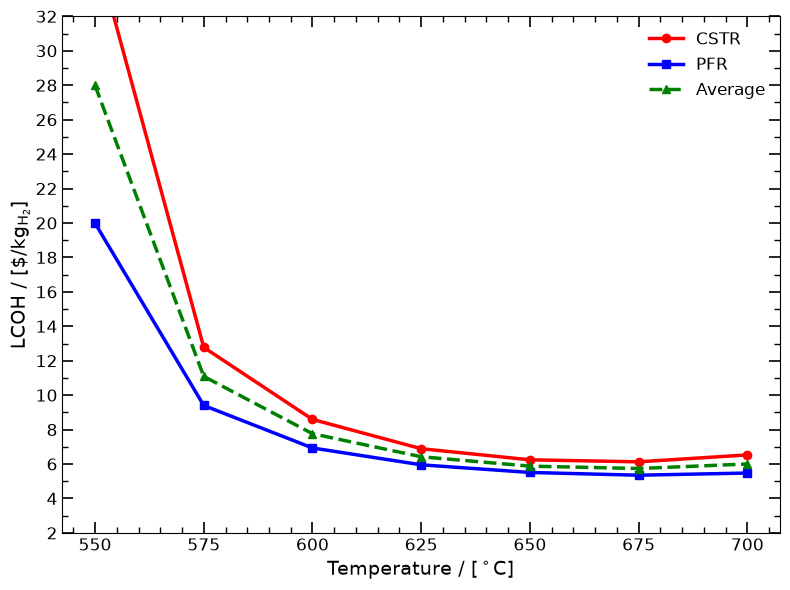

AVERAGE LCOH VS TEMPERATURE
  Temperature [°C]   Average LCOH [$/kg H2]
--------------------------------------------
             550.0                  27.9847
             575.0                  11.0888
             600.0                   7.7619
             625.0                   6.4225
             650.0                   5.8780
             675.0                   5.7399
             700.0                   6.0040


In [19]:
# LCOH PLOT vs TEMPERATURE
import numpy as np
from matplotlib.ticker import MultipleLocator

plt.style.use('default')

#Average CSTR/PFR
lcoh_values_mean = (
    np.asarray(lcoh_values_CSTR) + np.asarray(lcoh_values_PFR)
) / 2

fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    temperatures,
    lcoh_values_CSTR,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    temperatures,
    lcoh_values_PFR,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

#Curve average
ax.plot(
    temperatures,
    lcoh_values_mean,
    '--^',
    color='green',
    linewidth=2.5,
    markersize=6,
    label='Average'
)

ax.set_xlabel(r"Temperature / [$^\circ$C]", fontsize=14)
ax.set_ylabel(r"LCOH / [\$/kg$_{\mathrm{H}_2}$]", fontsize=14)


ax.xaxis.set_major_locator(MultipleLocator(25))
ax.xaxis.set_minor_locator(MultipleLocator(5))

ax.set_ylim(2, 32)
ax.yaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_minor_locator(MultipleLocator(1))


ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()
plt.show()

#print values
print("AVERAGE LCOH VS TEMPERATURE")
print("=" * 38)
print(f"{'Temperature [°C]':>18} {'Average LCOH [$/kg H2]':>24}")
print("-" * 44)

for temperature, average_lcoh in zip(
    temperatures,
    lcoh_values_mean
):
    print(
        f"{temperature:>18.1f} "
        f"{average_lcoh:>24.4f}"
    )

In [20]:
# Save avg LCOH temperature
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "NiMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

file_lcoh_temperature = results_dir / "LCOH_temperature.json"

# LCOH at different solid carbon selling prices (baseline price: 1.5 US$/kg)
import numpy as np
from copy import deepcopy

carbon_prices = [0.5, 1.5, 2.5]  # US$/kg


def lcoh_at_carbon_price(plant, carbon_price):
    """LCOH of a copy of the plant, with only the carbon selling price changed."""
    plant = deepcopy(plant)
    plant.plant_products["carbon"]["price"] = carbon_price
    return float(np.asarray(plant.calculate_levelized_cost(print_results=False)).item())


# Average of PFR and CSTR, for every temperature, at every carbon price
lcoh_by_carbon_price = {
    str(price): [
        (lcoh_at_carbon_price(pfr, price) + lcoh_at_carbon_price(cstr, price)) / 2
        for pfr, cstr in zip(plant_values_PFR, plant_values_CSTR)
    ]
    for price in carbon_prices
}

# Prepare JSON results
lcoh_temperature_results = {
    "temperature": [float(value) for value in temperatures],
    "lcoh_average": [float(value) for value in lcoh_values_mean],
    # keys are carbon prices in US$/kg; each list follows "temperature"
    "lcoh_average_by_carbon_price": lcoh_by_carbon_price,
}

# Save JSON
with open(file_lcoh_temperature, "w") as f:
    json.dump(lcoh_temperature_results, f, indent=4)

print(f"JSON saved in: {file_lcoh_temperature.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\NiMP\Results_TEA\LCOH_temperature.json


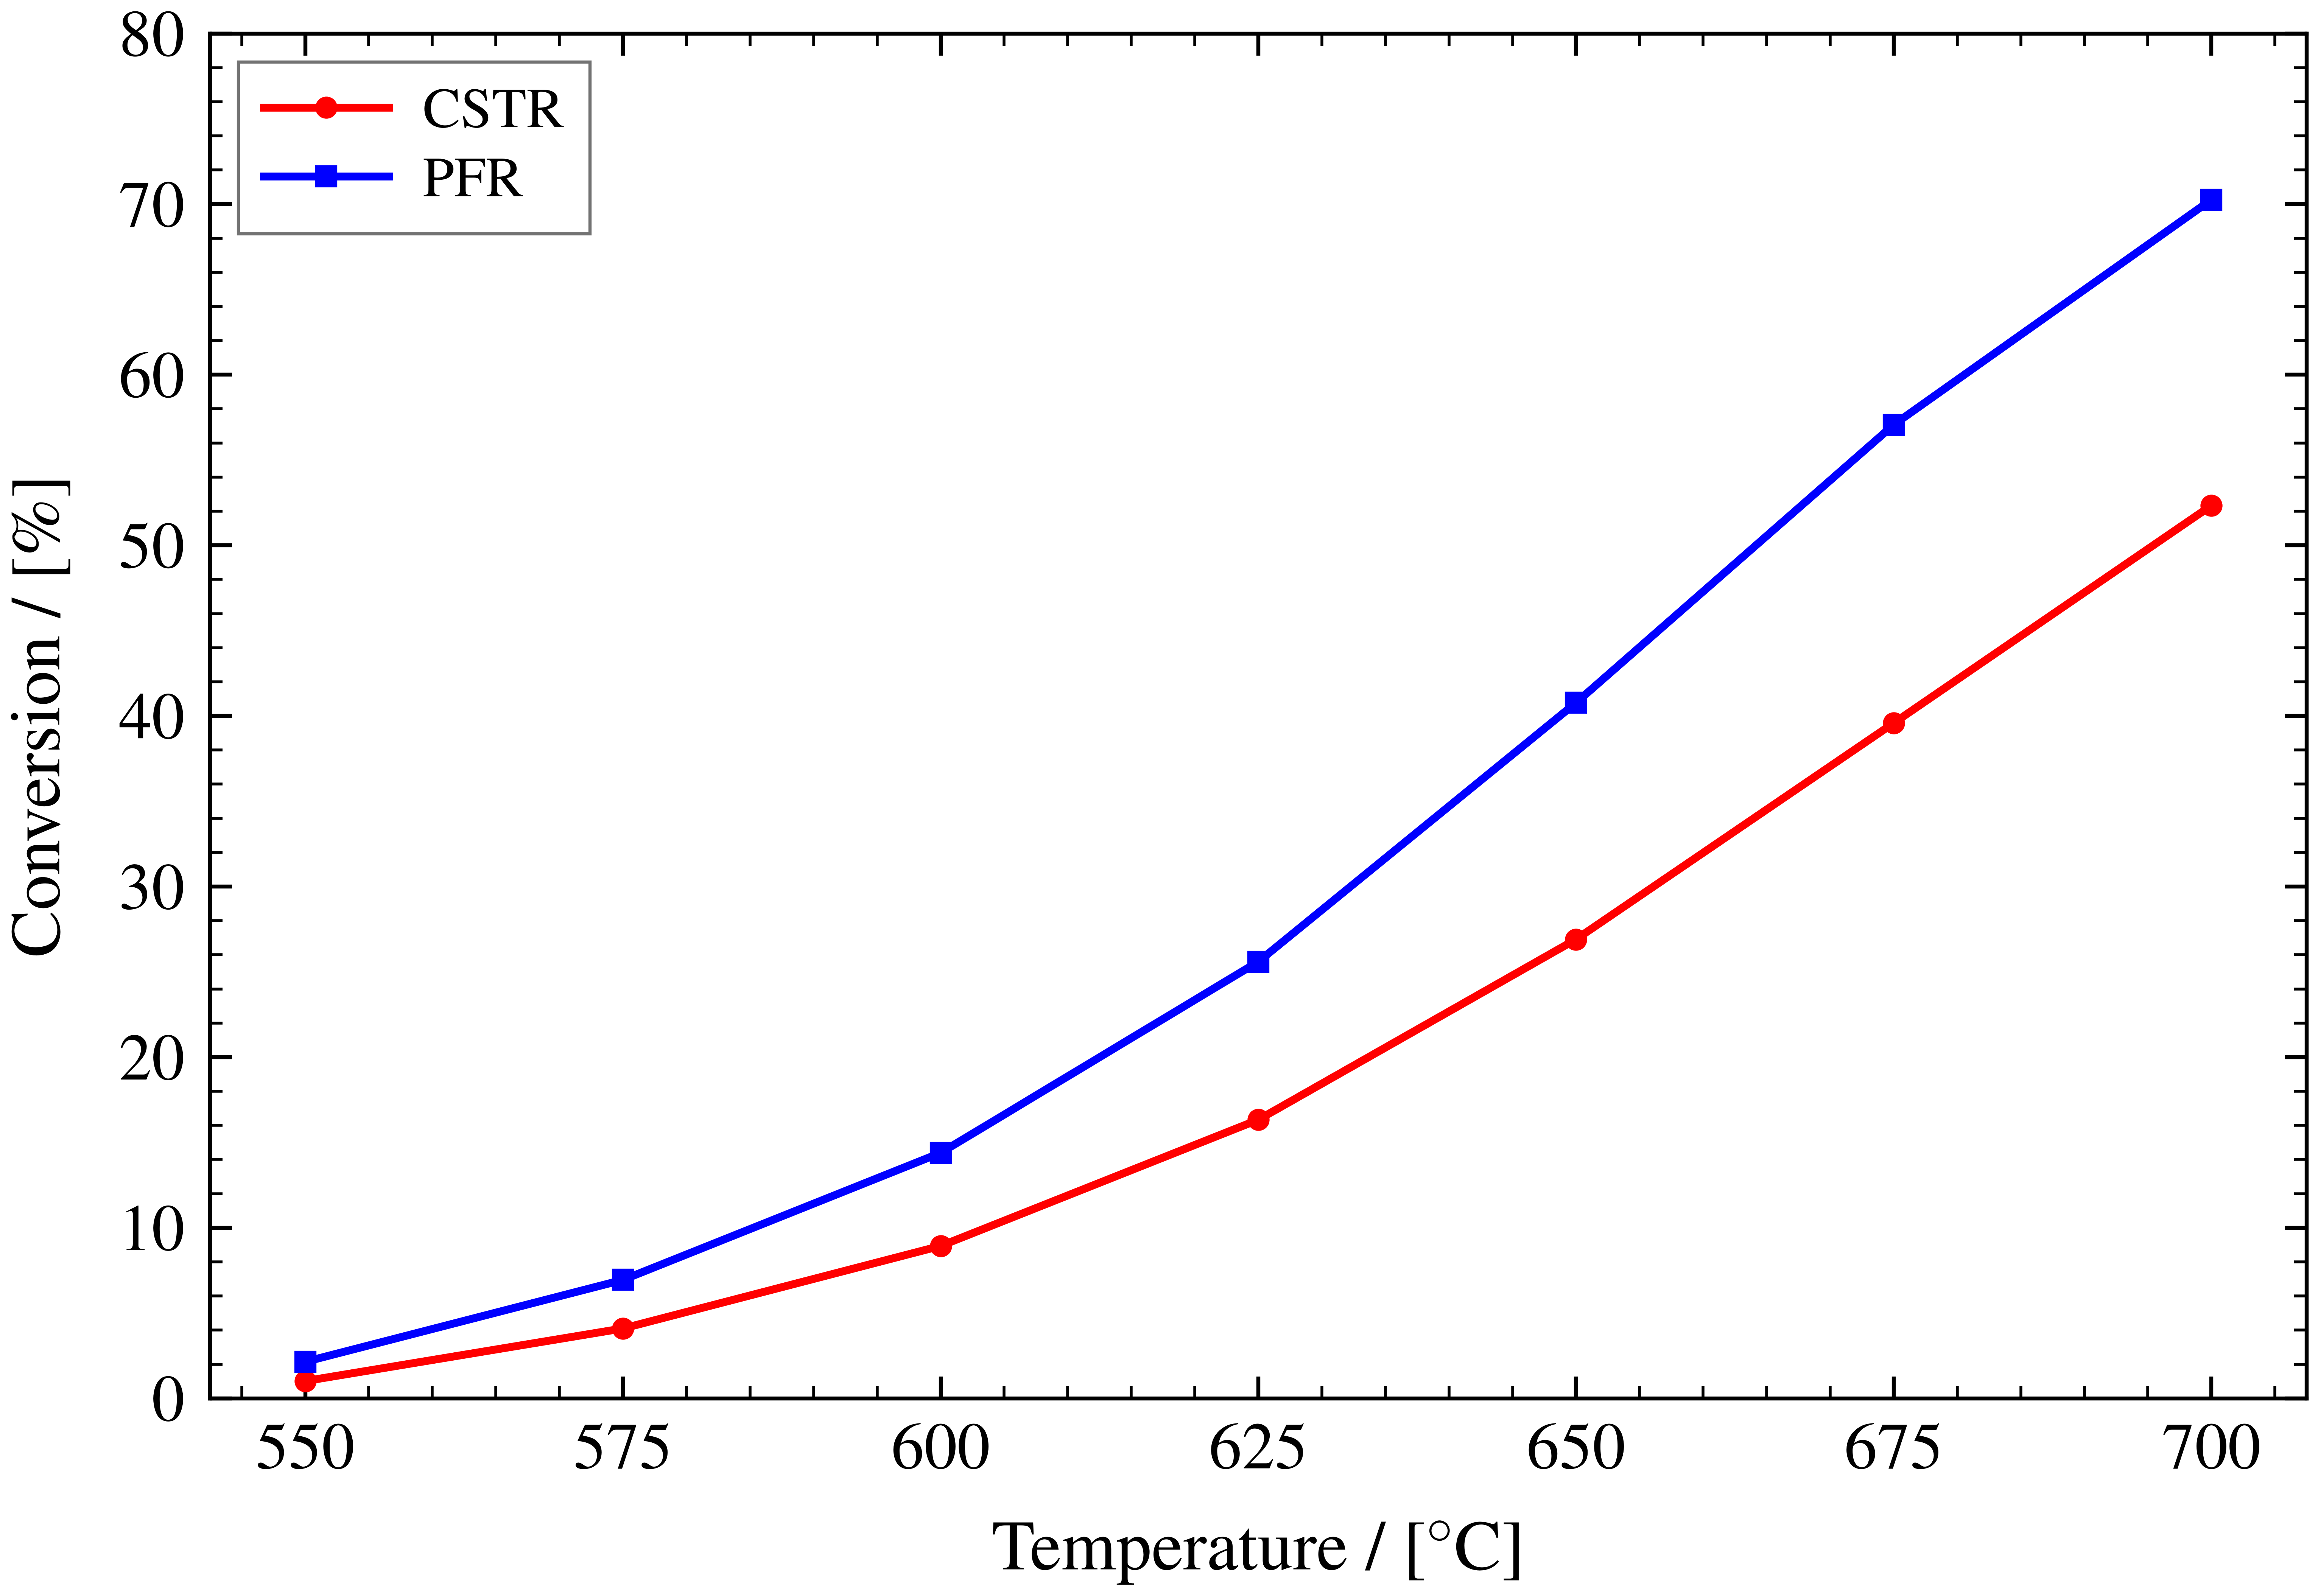

In [21]:
# CONVERSION VS TEMPERATURE
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scienceplots
from pathlib import Path
from matplotlib.ticker import MultipleLocator


plt.style.use(["science", "ieee"])

tick_font = 21.0
axis_label_font = 22.5
legend_font = 18.0

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "legend.fontsize": legend_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


fig, ax = plt.subplots(figsize=(10.8, 7.2))

#CSTR
ax.plot(
    temperatures,
    conversion_CSTR,
    "-o",
    color="red",
    linewidth=2.5,
    markersize=6,
    label="CSTR"
)


#PFR
ax.plot(
    temperatures,
    conversion_PFR,
    "-s",
    color="blue",
    linewidth=2.5,
    markersize=6,
    label="PFR"
)

ax.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=axis_label_font,
    labelpad=12
)

ax.set_ylabel(
    r"Conversion / [\%]",
    fontsize=axis_label_font,
    labelpad=14
)


ax.xaxis.set_major_locator(
    MultipleLocator(25)
)

ax.xaxis.set_minor_locator(
    MultipleLocator(5)
)

ax.set_ylim(
    0,
    80
)

ax.yaxis.set_major_locator(
    MultipleLocator(10)
)

ax.yaxis.set_minor_locator(
    MultipleLocator(2)
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    bottom=True,
    left=True,
    labelsize=tick_font,
    colors="black",
    length=7.0,
    width=1.25,
    pad=8
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    bottom=True,
    left=True,
    colors="black",
    length=4.0,
    width=0.9
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.25)

legend = ax.legend(
    loc="best",
    frameon=True,
    fancybox=False,
    framealpha=1.0,
    facecolor="white",
    edgecolor="0.45",
    fontsize=legend_font,
    handlelength=2.2,
    handletextpad=0.6,
    borderpad=0.45,
    labelspacing=0.30
)

legend.get_frame().set_linewidth(1.0)

fig.subplots_adjust(
    left=0.13,
    right=0.985,
    bottom=0.15,
    top=0.985
)

fig.savefig("conversion_vs_temperature.pdf",
    format="pdf"
)

plt.show()

In [ ]:
#SI: FIGURE S.11 - NI TEMPERATURE

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scienceplots
from pathlib import Path
from matplotlib.ticker import MultipleLocator

scale = 1.45

plt.style.use(["science", "ieee"])

tick_font = 21.0 * scale
axis_label_font = 22.5 * scale
legend_font = 16.5 * scale
panel_font = 21.5 * scale

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "legend.fontsize": legend_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

#Data arrays

temperatures = np.asarray(temperatures, dtype=float)

lcoh_values_CSTR = np.asarray(lcoh_values_CSTR, dtype=float)
lcoh_values_PFR = np.asarray(lcoh_values_PFR, dtype=float)
lcoh_values_mean = (lcoh_values_CSTR + lcoh_values_PFR) / 2.0

conversion_CSTR = np.asarray(conversion_CSTR, dtype=float)
conversion_PFR = np.asarray(conversion_PFR, dtype=float)

#Figure

fig, axs = plt.subplots(2, 2, figsize=(15.4 * scale, 11.2 * scale))

ax_a = axs[0, 0]
ax_b = axs[0, 1]

# Remove lower panels without changing upper panel geometry
axs[1, 0].remove()
axs[1, 1].remove()


def style_axes(ax):
    ax.tick_params(
        axis="x", which="major", direction="in",
        top=True, bottom=True, labelsize=tick_font,
        colors="black", length=5.8 * scale,
        width=1.1 * scale, pad=7 * scale
    )

    ax.tick_params(
        axis="y", which="major", direction="in",
        left=True, right=True, labelsize=tick_font,
        colors="black", length=5.8 * scale,
        width=1.1 * scale, pad=7 * scale
    )

    ax.tick_params(
        axis="x", which="minor", direction="in",
        top=True, bottom=True, colors="black",
        length=3.2 * scale, width=0.8 * scale
    )

    ax.tick_params(
        axis="y", which="minor", direction="in",
        left=True, right=True, colors="black",
        length=3.2 * scale, width=0.8 * scale
    )

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.1 * scale)

#Panel A LCOH

ax_a.plot(
    temperatures, lcoh_values_CSTR, "-o",
    color="red", linewidth=2.0 * scale,
    markersize=6 * scale, label="CSTR"
)

ax_a.plot(
    temperatures, lcoh_values_PFR, "-s",
    color="blue", linewidth=2.0 * scale,
    markersize=6 * scale,
    label="PFR"
)

ax_a.plot(
    temperatures, lcoh_values_mean, "--^",
    color="green", linewidth=2.0 * scale,
    markersize=6 * scale, label="Average"
)

ax_a.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=axis_label_font, labelpad=8 * scale
)

ax_a.set_ylabel(
    r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]",
    fontsize=axis_label_font, labelpad=10 * scale
)


ax_a.margins(x=0.05)
ax_a.xaxis.set_major_locator(MultipleLocator(25))
ax_a.xaxis.set_minor_locator(MultipleLocator(5))


ax_a.set_ylim(2, 42)
ax_a.yaxis.set_major_locator(MultipleLocator(5))
ax_a.yaxis.set_minor_locator(MultipleLocator(1))


legend_a = ax_a.legend(
    loc="best", fontsize=legend_font,
    frameon=True, fancybox=False, framealpha=1.0,
    facecolor="white", edgecolor="0.50",
    handlelength=1.35 * scale,
    handletextpad=0.35 * scale,
    borderpad=0.30 * scale,
    labelspacing=0.22 * scale
)

legend_a.get_frame().set_linewidth(0.8 * scale)
style_axes(ax_a)

#Panel B Conversion

ax_b.plot(
    temperatures, conversion_CSTR, "-o",
    color="red", linewidth=2.5 * scale,
    markersize=6 * scale, label="CSTR"
)

ax_b.plot(
    temperatures, conversion_PFR, "-s",
    color="blue", linewidth=2.5 * scale,
    markersize=6 * scale, label="PFR"
)

ax_b.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=axis_label_font, labelpad=8 * scale
)

ax_b.set_ylabel(
    r"Conversion / [\%]",
    fontsize=axis_label_font, labelpad=10 * scale
)

ax_b.margins(x=0.05)
ax_b.xaxis.set_major_locator(MultipleLocator(25))
ax_b.xaxis.set_minor_locator(MultipleLocator(5))


ax_b.set_ylim(0, 82)
ax_b.yaxis.set_major_locator(MultipleLocator(16))
ax_b.yaxis.set_minor_locator(MultipleLocator(4))

legend_b = ax_b.legend(
    loc="lower right", fontsize=legend_font,
    frameon=True, fancybox=False, framealpha=1.0,
    facecolor="white", edgecolor="0.50",
    handlelength=1.35 * scale,
    handletextpad=0.35 * scale,
    borderpad=0.30 * scale,
    labelspacing=0.22 * scale
)

legend_b.get_frame().set_linewidth(0.8 * scale)
style_axes(ax_b)


ax_a.text(
    0.5, -0.195, r"(a)", transform=ax_a.transAxes,
    ha="center", va="top", fontsize=panel_font
)

ax_b.text(
    0.5, -0.195, r"(b)", transform=ax_b.transAxes,
    ha="center", va="top", fontsize=panel_font
)


fig.subplots_adjust(
    left=0.085,
    right=0.985,
    bottom=0.090,
    top=0.985,
    wspace=0.24,
    hspace=0.36
)


fig.savefig("Ni_twopanel_temperature.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()


C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\.venv\Lib\site-packages\openpytea\plotting.py:520: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  created_fig.tight_layout()


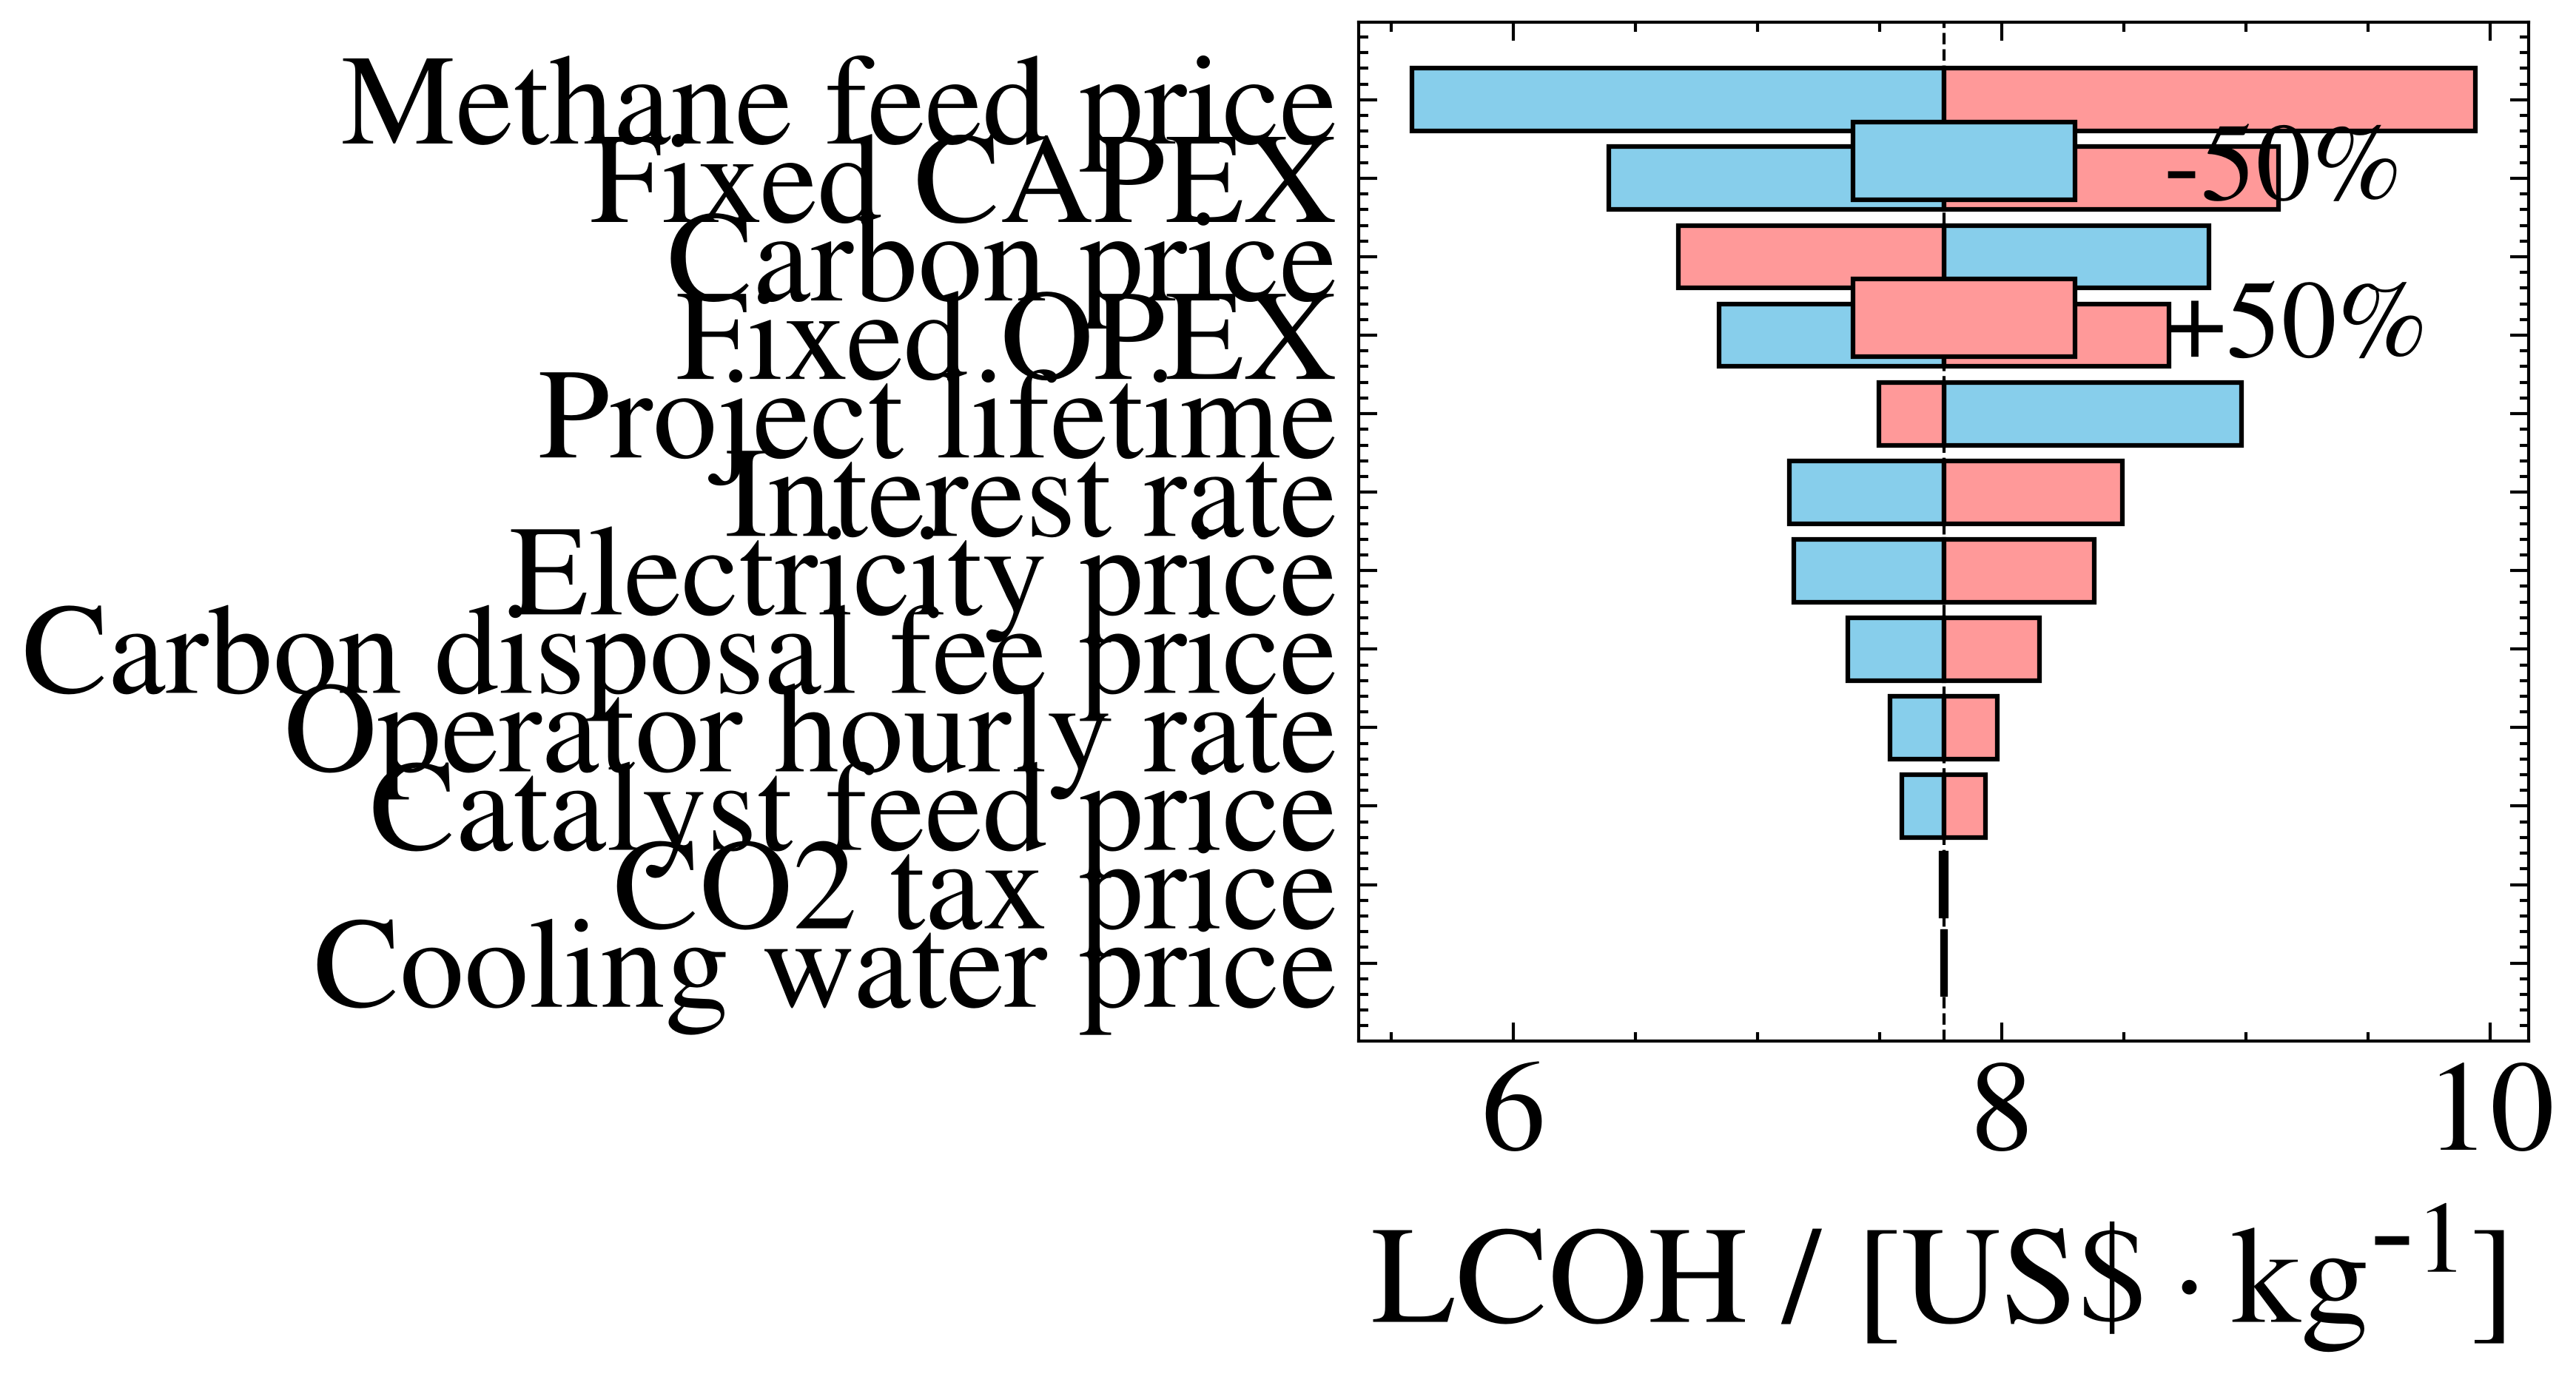

In [22]:
#SI: FIGURE S.14 - TORNADO NI
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

#Tornado plot

tornado_PFR = tornado_data(plant=plant_values_PFR[idx], plus_minus_value=0.5, metric="LCOP")
tornado_CSTR = tornado_data(plant=plant_values_CSTR[idx], plus_minus_value=0.5, metric="LCOP")

#Avg CSTR/PFR
def average_tornado_data(data_pfr, data_cstr):

    pfr_results = {
        factor: {"low": low, "high": high, "label": label}
        for factor, low, high, label in zip(
            data_pfr["factors"], data_pfr["lows"], data_pfr["highs"], data_pfr["labels"]
        )
    }

    cstr_results = {
        factor: {"low": low, "high": high, "label": label}
        for factor, low, high, label in zip(
            data_cstr["factors"], data_cstr["lows"], data_cstr["highs"], data_cstr["labels"]
        )
    }

    if set(pfr_results) != set(cstr_results):
        raise ValueError("PFR and CSTR do not contain the same sensitivity parameters.")

    averaged_results = []

    for factor in pfr_results:
        average_low = (pfr_results[factor]["low"] + cstr_results[factor]["low"]) / 2
        average_high = (pfr_results[factor]["high"] + cstr_results[factor]["high"]) / 2
        label = pfr_results[factor]["label"]
        averaged_results.append((factor, average_low, average_high, label))

    averaged_results.sort(key=lambda result: abs(result[2] - result[1]))

    return {
        "factors": [result[0] for result in averaged_results],
        "lows": np.array([result[1] for result in averaged_results]),
        "highs": np.array([result[2] for result in averaged_results]),
        "labels": [result[3] for result in averaged_results],
        "base_value": (data_pfr["base_value"] + data_cstr["base_value"]) / 2,
        "plus_minus_value": data_pfr["plus_minus_value"],
        "metric": "LCOP",
        "xlabel": r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]"
    }

tornado_average = average_tornado_data(tornado_PFR, tornado_CSTR)

fig, ax = plot_tornado(tornado_average)

ax.set_xlabel(r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]")
ax.set_title("")

fig.savefig("LCOH_tornado.pdf", format="pdf")

plt.show()

Monte Carlo:   0%|          | 0/100 [00:00<?, ?it/s]

Monte Carlo:   1%|          | 1/100 [00:00<00:42,  2.32it/s]

Monte Carlo:   2%|▏         | 2/100 [00:01<00:52,  1.88it/s]

Monte Carlo:   3%|▎         | 3/100 [00:01<00:56,  1.72it/s]

Monte Carlo:   4%|▍         | 4/100 [00:02<00:58,  1.64it/s]

Monte Carlo:   5%|▌         | 5/100 [00:03<01:05,  1.45it/s]

... (194 outputs left out)

Monte Carlo:  98%|█████████▊| 98/100 [00:41<00:00,  2.79it/s]

Monte Carlo:  99%|█████████▉| 99/100 [00:41<00:00,  2.85it/s]

Monte Carlo: 100%|██████████| 100/100 [00:42<00:00,  2.86it/s]

Monte Carlo: 100%|██████████| 100/100 [00:42<00:00,  2.36it/s]

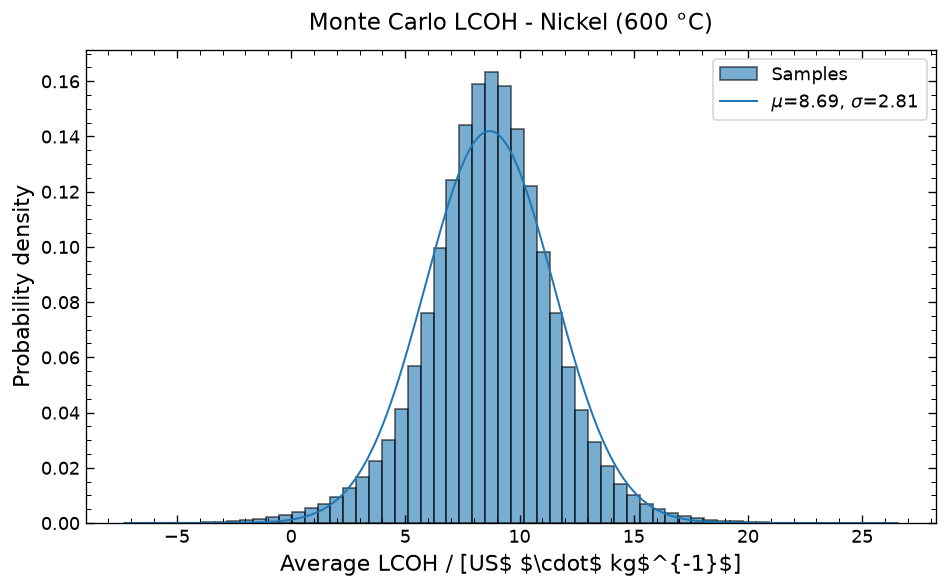

In [23]:
# Monte Carlo simulations on economic variables

import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
from scipy.optimize import brentq
from scipy.stats import norm, truncnorm
from openpytea.analysis import make_distribution
from openpytea.analysis import monte_carlo
from openpytea.plotting import plot_monte_carlo

num_samples, batch_size, num_bins, seed = 1_000_000, 10_000, 60, 12345

# New distributions

# Carbon selling price ($/kg): lognormal (OpenPyTEA dist_id 2)
carbon_price, carbon_std, carbon_max, carbon_min = 1.5, 1.5, 6.0, 0.5

# Carbon disposal fee ($/kg): lognormal (OpenPyTEA dist_id 2)
disposal_price, disposal_std, disposal_max, disposal_min = 1.0, 1.0, 4.0, 0.25

# Fraction of total solids sold: lognormal, tail towards low values
sale_fraction, sale_fraction_std, sale_fraction_max, sale_fraction_min = 0.50, 0.2, 1.0, 0.0

# Update plant and solid streams

def prepare_ni_plant(original_plant):
    plant = deepcopy(original_plant)
    total_solids_day = (
        float(plant.plant_products["carbon"]["production"])
        + float(plant.variable_opex_inputs["carbon_disposal_fee"]["consumption"])
    )
    if not np.isfinite(total_solids_day) or total_solids_day <= 0:
        raise ValueError("Invalid Ni solid flow in plant configuration")

    plant.plant_products["carbon"].update({
        "production": total_solids_day * sale_fraction,
        "price": carbon_price, "std": carbon_std,
        "min": carbon_min, "max": carbon_max,
    })
    plant.variable_opex_inputs["carbon_disposal_fee"].update({
        "consumption": total_solids_day * (1 - sale_fraction),
        "price": disposal_price, "std": disposal_std,
        "min": disposal_min, "max": disposal_max,
    })
    return plant, total_solids_day

plant_PFR_Ni, total_solids_PFR_Ni = prepare_ni_plant(plant_values_PFR[idx])
plant_CSTR_Ni, total_solids_CSTR_Ni = prepare_ni_plant(plant_values_CSTR[idx])

# Sampling

base_mc_PFR_Ni = monte_carlo(
    plant_PFR_Ni, num_samples=num_samples,
    batch_size=batch_size, random_seed=seed,
)
base_mc_CSTR_Ni = monte_carlo(
    plant_CSTR_Ni, num_samples=num_samples,
    batch_size=batch_size, random_seed=seed,
)

shared_economic_inputs = [
    "Fixed capital factor", "Fixed opex factor", "Operator hourly rate",
    "Project lifetime", "Interest rate", "Electricity price",
    "Methane Feed price", "Catalyst Feed price", "Cooling Water price",
    "Co2 Tax price",
]

for key in shared_economic_inputs:
    if key not in base_mc_PFR_Ni["inputs"] or key not in base_mc_CSTR_Ni["inputs"]:
        raise KeyError(f"Missing OpenPyTEA input: {key}")
    x = np.asarray(base_mc_PFR_Ni["inputs"][key])
    y = np.asarray(base_mc_CSTR_Ni["inputs"][key])
    if not np.array_equal(x, y, equal_nan=True):
        raise ValueError(f"Unaligned PFR/CSTR draws for '{key}'")

# Distributions

def draw_truncated_normal(rng, mean, sigma, minimum, maximum, size):
    low = (minimum - mean) / sigma
    high = (maximum - mean) / sigma
    u = np.clip(rng.random(size), 1e-12, 1 - 1e-12)
    return truncnorm.ppf(u, low, high, loc=mean, scale=sigma)

def lognormal_quantile(u, mean, std, minimum, maximum, tail="high"):
    """Quantiles ``u`` of OpenPyTEA's lognormal (dist_id 2) truncated to [minimum, maximum].

    tail="high": long tail towards the maximum (standard lognormal).
    tail="low":  long tail towards the minimum (lognormal mirrored at the maximum,
                 x = maximum - Y). Quantiles still increase with ``u``.
    sigma (of ln x) is matched to ``std``; mu is tuned so that the mean of the
    truncated distribution equals ``mean``.
    """
    if tail == "low":
        return maximum - lognormal_quantile(1 - np.asarray(u), maximum - mean, std,
                                            0.0, maximum - minimum, tail="high")

    sigma = np.sqrt(np.log(1 + (std / mean) ** 2))
    log_low = np.log(minimum) if minimum > 0 else -np.inf
    log_high = np.log(maximum)

    def truncated_mean_gap(mu):
        # E[x | minimum <= x <= maximum] - mean, closed form for a lognormal
        a, b = (log_low - mu) / sigma, (log_high - mu) / sigma
        mass = norm.cdf(b) - norm.cdf(a)
        return np.exp(mu + sigma**2 / 2) * (norm.cdf(b - sigma) - norm.cdf(a - sigma)) / mass - mean

    # Bracket: low mu -> truncated mean near the minimum; high mu -> near the maximum
    mu = brentq(truncated_mean_gap, np.log(mean) - 5 * sigma - 1, log_high + 3 * sigma)
    dist = make_distribution(2, loc=mu, scale=sigma)
    low, high = dist.cdf(minimum), dist.cdf(maximum)
    return dist.ppf(low + np.asarray(u) * (high - low))

def draw_lognormal(rng, mean, std, minimum, maximum, size, tail="high"):
    u = np.clip(rng.random(size), 1e-12, 1 - 1e-12)
    return lognormal_quantile(u, mean, std, minimum, maximum, tail)

rng = np.random.default_rng(seed + 1)

carbon_selling_price_Ni = draw_lognormal(
    rng, carbon_price, carbon_std, carbon_min, carbon_max, num_samples
)
carbon_disposal_fee_Ni = draw_lognormal(
    rng, disposal_price, disposal_std, disposal_min, disposal_max, num_samples
)
carbon_sale_fraction_Ni = draw_lognormal(
    rng, sale_fraction, sale_fraction_std, sale_fraction_min, sale_fraction_max, num_samples, tail="low"
)

#Sold and disposed solids

def ni_solid_streams(total_solids_day):
    sold = carbon_sale_fraction_Ni * total_solids_day
    disposed = (1 - carbon_sale_fraction_Ni) * total_solids_day
    if not np.allclose(sold + disposed, total_solids_day):
        raise AssertionError("Ni sold/disposed mass balance not satisfied")
    return {
        "sold": sold,
        "disposed": disposed,
        "total_solids": np.full(num_samples, total_solids_day),
    }

streams_PFR_Ni = ni_solid_streams(total_solids_PFR_Ni)
streams_CSTR_Ni = ni_solid_streams(total_solids_CSTR_Ni)

# Updated LCOH

def evaluate_ni_mc(plant, base_mc, streams, name):
    inputs = {
        key: np.asarray(value).copy()
        for key, value in base_mc["inputs"].items()
    }

    # Override the three independently sampled carbon-related inputs.
    inputs["Carbon product price"] = carbon_selling_price_Ni.copy()
    inputs["Carbon Disposal Fee price"] = carbon_disposal_fee_Ni.copy()
    inputs["Carbon production"] = streams["sold"].copy()
    inputs["Carbon Disposal Fee consumption"] = streams["disposed"].copy()
    inputs["Carbon sale fraction"] = carbon_sale_fraction_Ni.copy()
    inputs["Total solids (kg/day)"] = streams["total_solids"].copy()

    lcoh_samples = np.empty(num_samples, dtype=float)

    for start in range(0, num_samples, batch_size):
        stop = min(start + batch_size, num_samples)
        s = slice(start, stop)
        p = deepcopy(plant)

        p.operator_hourly_rate["rate"] = inputs["Operator hourly rate"][s]
        changes = {
            "project_lifetime": inputs["Project lifetime"][s],
            "interest_rate": inputs["Interest rate"][s],
        }
        if "Plant utilization" in inputs:
            changes["plant_utilization"] = inputs["Plant utilization"][s]
        if "Tax rate" in inputs:
            changes["tax_rate"] = inputs["Tax rate"][s]
        p.update_configuration(changes)

        for item in plant.variable_opex_inputs:
            label = item.replace("_", " ").title()
            p.variable_opex_inputs[item]["price"] = inputs[f"{label} price"][s]
            p.variable_opex_inputs[item]["consumption"] = inputs[f"{label} consumption"][s]

        for product in plant.plant_products:
            label = product.replace("_", " ").title()
            price_key = f"{label} product price"
            if price_key in inputs:
                p.plant_products[product]["price"] = inputs[price_key][s]
            p.plant_products[product]["production"] = inputs[f"{label} production"][s]

        p.calculate_fixed_capital(fc=inputs["Fixed capital factor"][s])
        p.calculate_variable_opex()
        p.calculate_fixed_opex(fp=inputs["Fixed opex factor"][s])
        p.calculate_cash_flow()
        p.calculate_levelized_cost()

        # Unclipped LCOH: OpenPyTEA floors the LCOP at 0, but negative values
        # (carbon revenue above all costs) are kept here
        disc_capex, disc_opex, disc_side_rev, disc_prod = p._discounted_totals()
        values = np.ravel((disc_capex + disc_opex - disc_side_rev) / disc_prod)
        if values.size != stop - start:
            raise ValueError(f"Unexpected number of LCOH values in {name}: {values.size}")
        lcoh_samples[s] = values

    if not np.isfinite(lcoh_samples).all():
        raise ValueError(f"Non-finite LCOH values in {name}")

    return {
        "name": name,
        "metrics": {"LCOP": lcoh_samples},
        "inputs": inputs,
        "num_samples": num_samples,
        "additional_capex": False,
        "currency": base_mc.get("currency", r"\$"),
    }

mc_results_PFR_Ni = evaluate_ni_mc(
    plant_PFR_Ni, base_mc_PFR_Ni, streams_PFR_Ni, "PFR - Nickel"
)

mc_results_CSTR_Ni = evaluate_ni_mc(
    plant_CSTR_Ni, base_mc_CSTR_Ni, streams_CSTR_Ni, "CSTR - Nickel"
)

# Average LCOH

lcoh_mc_average_Ni = (
    mc_results_PFR_Ni["metrics"]["LCOP"]
    + mc_results_CSTR_Ni["metrics"]["LCOP"]
) / 2

mc_results_average_Ni = deepcopy(mc_results_PFR_Ni)
mc_results_average_Ni["name"] = "Average PFR-CSTR - Nickel"
mc_results_average_Ni["metrics"] = {"LCOP": lcoh_mc_average_Ni}


with plt.style.context("default"):
    fig, ax = plot_monte_carlo(
        mc_results_average_Ni, metric="LCOP", bins=num_bins,
        figsize=(8, 5), show=False,
    )
    fig.set_dpi(120)
    fig.set_facecolor("white")
    ax.set_facecolor("white")
    ax.set_title(
        f"Monte Carlo LCOH - Nickel ({temperatures[idx]} °C)",
        fontsize=14, pad=12,
    )
    ax.set_xlabel(r"Average LCOH / [US$ $\cdot$ kg$^{-1}$]", fontsize=13)
    ax.set_ylabel("Probability density", fontsize=13)
    ax.tick_params(axis="both", which="major", direction="in",
                   top=True, right=True, labelsize=11, length=5)
    ax.minorticks_on()
    ax.tick_params(axis="both", which="minor", direction="in",
                   top=True, right=True, length=3)
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(loc="upper right", fontsize=11, frameon=True)
    fig.tight_layout()
    plt.show()


In [ ]:
##SI: - MC INPUTS NI

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scienceplots

from pathlib import Path
from openpytea.plotting import plot_monte_carlo_inputs

plt.style.use(["science", "ieee"])

font_scale = 1.10
tick_font = 13.5 * font_scale
title_font = 14.5 * font_scale
axis_label_font = 14.0 * font_scale

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.titlesize": title_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

#Select MC inputs
mc_inputs = mc_results_average_Ni["inputs"]

def normalize_key(key):
    return " ".join(str(key).lower().replace("_", " ").replace("-", " ").split())

parameter_groups = [
    ("Fixed capital factor",),
    ("Fixed opex factor",),
    ("Operator hourly rate",),
    ("Project lifetime",),
    ("Interest rate",),
    ("Electricity price",),
    ("Methane Feed price", "Methane price"),
    ("Catalyst Feed price", "Catalyst price"),
    ("Cooling Water price", "Cooling water price"),
    ("CO2 Tax price", "Co2 Tax price"),
    ("Carbon product price", "Carbon selling price"),
    ("Carbon Disposal Fee price", "Carbon disposal fee"),
    ("Carbon sale fraction", "Fraction sold", "Sale fraction")
]

selected_inputs = {}

for aliases in parameter_groups:
    alias_norm = [normalize_key(alias) for alias in aliases]
    match = next((key for key in mc_inputs if normalize_key(key) in alias_norm), None)

    if match is not None:
        selected_inputs[match] = mc_inputs[match]

mc_results_plot = dict(mc_results_average_Ni)
mc_results_plot["inputs"] = selected_inputs

#Plot
fig, axes = plot_monte_carlo_inputs(mc_results_plot, category="economic", bins=40, show=False)
fig.set_facecolor("white")

if getattr(fig, "_suptitle", None) is not None:
    fig._suptitle.set_visible(False)

for txt in fig.texts:
    if txt.get_text().strip().lower() == "economic parameters":
        txt.set_visible(False)


label_map = {
    "fixed capital factor": r"Fixed capital factor / [-]",
    "fixed opex factor": r"Fixed OPEX factor / [-]",
    "operator hourly rate": r"Operator hourly rate / [US\$·h$^{-1}$]",
    "project lifetime": r"Project lifetime / [years]",
    "interest rate": r"Interest rate / [-]",
    "electricity price": r"Electricity price / [US\$·kWh$^{-1}$]",
    "methane feed price": r"Methane feed price / [US\$·kg$^{-1}$]",
    "methane price": r"Methane feed price / [US\$·kg$^{-1}$]",
    "catalyst feed price": r"Catalyst price / [US\$·kg$^{-1}$]",
    "catalyst price": r"Catalyst price / [US\$·kg$^{-1}$]",
    "cooling water price": r"Cooling water price / [US\$·MJ$^{-1}$]",
    "co2 tax price": r"$\mathrm{CO}_2$ tax rate / [US\$·kg$^{-1}$]",
    "carbon product price": r"Carbon selling price / [US\$·kg$^{-1}$]",
    "carbon selling price": r"Carbon selling price / [US\$·kg$^{-1}$]",
    "carbon disposal fee price": r"Carbon disposal fee / [US\$·kg$^{-1}$]",
    "carbon disposal fee": r"Carbon disposal fee / [US\$·kg$^{-1}$]",
    "carbon sale fraction": r"Fraction sold / [-]",
    "fraction sold": r"Fraction sold / [-]",
    "sale fraction": r"Fraction sold / [-]"
}

axes_flat = np.asarray(axes).ravel()

for ax in axes_flat:
    if not ax.get_visible() or not ax.axison:
        continue

    current_title = ax.get_title()
    current_title_norm = normalize_key(current_title)
    xlabel = label_map.get(current_title_norm, current_title)

    ax.set_title("")
    ax.set_xlabel(xlabel, fontsize=axis_label_font, labelpad=8)
    ax.xaxis.label.set_fontsize(axis_label_font)
    ax.yaxis.label.set_fontsize(axis_label_font)
    ax.set_facecolor("white")

    ax.tick_params(axis="both", which="major", direction="in", top=True, bottom=True, left=True, right=True,
                   labelsize=tick_font, colors="black", length=5.5, width=1.0, pad=5)

    ax.minorticks_on()

    ax.tick_params(axis="both", which="minor", direction="in", top=True, bottom=True, left=True, right=True,
                   colors="black", length=3.0, width=0.8)

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.0)

n_parameters = len(selected_inputs)
n_rows = int(np.ceil(n_parameters / 3))

fig.set_size_inches(14.4, 11.4 * n_rows / 4)

#Layout
fig.subplots_adjust(
    left=0.070,
    right=0.985,
    bottom=0.070,
    top=0.975,
    wspace=0.28,
    hspace=0.40
)

fig.savefig("mc_inputs__Ni.pdf", format="pdf")

plt.show()


In [24]:
# Save Monte Carlo results
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "NiMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

mc_file = results_dir / "LCOH_MonteCarlo.json"

# Prepare Monte Carlo results
mc_export = {
    "name": "Nickel",
    "temperature": float(temperatures[idx]),
    "metrics": {
        "LCOP": lcoh_mc_average_Ni.tolist()
    },
    # Sampled carbon-related inputs, for plotting their distributions
    "inputs": {
        "Carbon selling price [US$/kg]": carbon_selling_price_Ni.tolist(),
        "Carbon disposal fee [US$/kg]": carbon_disposal_fee_Ni.tolist(),
        "Carbon fraction sold [-]": carbon_sale_fraction_Ni.tolist(),
    }
}

# Save JSON
with open(mc_file, "w") as f:
    json.dump(mc_export, f, indent=4)

print(f"JSON saved in: {mc_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\NiMP\Results_TEA\LCOH_MonteCarlo.json
